# Feature engineering

**Objetivo.** Partir de `matches_clean.csv` (generado por `01_eda.ipynb`: 36,150 partidos de 2014/15 a 2025/26, valores observados y sin imputar) y construir **todas** las variables del proyecto, en dos partes:

- **Variables base** (Pasos 1–10): forma reciente, mercado, calidad de plantilla y habilidades, ordenadas en los conjuntos **F1** (sin NaN) y **F2** (completo). Son los bloques de información con los que `04_modelo.ipynb` responde si algo aporta sobre el precio.
- **Variables nuevas** (Pasos 11–15): variables pensadas para el problema —fuerza de equipo con memoria larga (Elo, medias exponenciales, goles esperados), tendencia al empate, contexto del partido (descanso, fase de temporada, equipos recién ascendidos) y señales del propio mercado (precio de Pinnacle, dispersión entre casas)— y una **revisión** de todas las variables (las de antes y las nuevas) con un veredicto de qué conservar.

**Referencia.** Zheng & Casari, *Feature Engineering for Machine Learning* (cap. 2: sanity checks numéricos y selección *filter*; cap. 5: *back-off* hacia el prior, estadísticas acotadas y control de leakage).

## Paso 0 — Carga de datos

**Qué vamos a hacer.** Cargar dos fuentes:

1. `matches_clean.csv`: dataset limpio del EDA, con los valores **observados** (cuotas y estadísticas con NaN donde la fuente no las publica; plantilla completa).
2. `matches_warmup.csv`: temporada 2013/14, solo para dar historial a los equipos en 2014/15.

De la primera se separan las cuotas de apertura de las casas con cobertura ≥ 85% (Bet365, BetWin, Pinnacle, William Hill), la cuota de cierre de Pinnacle (solo para el backtest) y las estadísticas de partido.

**Por qué.** El EDA ya no imputa nada, así que ya no hay que volver a la base cruda: lo que se lee aquí es exactamente lo que se decidió allí. Vcbet (83.2% de cobertura, 100% de nulos desde 2024/25) queda fuera del mercado por no superar el 85%.

In [20]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
warnings.filterwarnings('ignore', message='Mean of empty slice')

df_clean = pd.read_csv("../data/matches_clean.csv")
CUOTAS = [c for c in df_clean.columns if re.fullmatch(r'(B365|BW|PS|WH|VC|PSC)[HDA]', c)]      # cuotas que conservó el EDA (observadas, con NaN)

# Cuotas de las casas con cobertura >= 85% (B365, BW, Pinnacle, WH): apertura para el mercado y cierre de Pinnacle solo para el backtest
ODDS_RAW_COLS = ['B365H', 'B365D', 'B365A', 'BWH', 'BWD', 'BWA', 'PSH', 'PSD', 'PSA', 'WHH', 'WHD', 'WHA', 'PSCH', 'PSCD', 'PSCA']
raw_odds = df_clean[['Date', 'HomeTeam', 'AwayTeam'] + ODDS_RAW_COLS].copy()

# Estadisticas observadas (con NaN) y temporada de calentamiento
STAT_COLS = ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']
_u = ['Div', 'Season', 'Date', 'HomeTeam', 'AwayTeam', 'FTR'] + STAT_COLS
raw_stats = df_clean[_u].copy()
warm = pd.read_csv("../data/matches_warmup.csv", usecols=_u)

print('matches_clean:', df_clean.shape)
print('partidos modelables:', len(raw_stats), '| temporadas:', sorted(raw_stats['Season'].unique()))
print('partidos de calentamiento (solo historial):', len(warm), '| temporada', warm['Season'].unique().tolist())

matches_clean: (36150, 74)
partidos modelables: 36150 | temporadas: [np.int64(1415), np.int64(1516), np.int64(1617), np.int64(1718), np.int64(1819), np.int64(1920), np.int64(2021), np.int64(2122), np.int64(2223), np.int64(2324), np.int64(2425), np.int64(2526)]
partidos de calentamiento (solo historial): 2918 | temporada [1314]


**Qué encontramos.** Se cargaron 36,150 partidos modelables (12 temporadas, 2014/15–2025/26) y 2,918 partidos de calentamiento (2013/14).

**Qué significa para nuestro caso.** Una sola fuente de verdad: si cambia la limpieza del EDA, todo lo que sigue se recalcula sin pasos intermedios.

## Paso 1 — Forma de los últimos 5 partidos (con calentamiento y ventana acolchada)

**Qué vamos a hacer.** Convertir cada partido en dos registros (local y visitante) con las estadísticas desde el lado del equipo, y calcular para cada uno la media de sus **últimos 5 partidos sin incluir el actual**. El resultado se une de vuelta como `H_*_5` (forma del local) y `A_*_5` (forma del visitante).

**Decisiones de diseño** (cap. 5 de Zheng & Casari: *back-off* hacia el prior; no fabricar datos):

- **Calentamiento:** los partidos de 2013/14 entran al historial pero no se modelan. Así la jornada 1 de 2014/15 ya tiene forma real.
- **Estadísticas observadas:** si la fuente no publica tiros/córners/faltas/tarjetas para un partido, el valor es NaN y no se inventa.
- **Ventana acolchada:** si en los últimos 5 partidos hay solo `n` valores observados, los `5−n` restantes valen la media de su liga **estrictamente anterior a la fecha** (solo valores observados). Una ventana completa no cambia. Si la liga aún no tiene ningún valor observado de esa estadística, el resultado es NaN.
- Goles, puntos, victorias y portería a cero salen de `FTHG/FTAG/FTR`, que siempre existen.

In [21]:
# Base: partidos de calentamiento + partidos modelables, en orden cronologico
base = pd.concat([warm.assign(is_warm=True), raw_stats.assign(is_warm=False)], ignore_index=True)
for col in STAT_COLS:
    base[col] = pd.to_numeric(base[col], errors='coerce')
base['match_id'] = np.where(base['is_warm'], -1, np.arange(len(base)) - len(warm))   # fila en df_clean (-1 = calentamiento)
base['Date_dt'] = pd.to_datetime(base['Date'], dayfirst=True, format='mixed', errors='coerce')
assert base['Date_dt'].notna().all(), 'fechas sin parsear'
base = base.sort_values(['Date_dt', 'is_warm', 'match_id'], ascending=[True, False, True]).reset_index(drop=True)
base['seq'] = np.arange(len(base))

ev_rows = []
for lado, col in [('H', 'HomeTeam'), ('A', 'AwayTeam')]:
    e = base.copy()
    local = e['HomeTeam'] == e[col]
    e['Team'] = e[col]
    e['lado'] = lado
    e['GF'] = np.where(local, e['FTHG'], e['FTAG'])
    e['GA'] = np.where(local, e['FTAG'], e['FTHG'])
    ganador = 'H' if lado == 'H' else 'A'
    e['WinRate'] = (e['FTR'] == ganador).astype(float)
    e['Pts'] = np.select([e['FTR'] == ganador, e['FTR'] == 'D'], [3, 1], 0)
    e['SGF'], e['SGA'] = np.where(local, e['HS'], e['AS']), np.where(local, e['AS'], e['HS'])
    e['SOTF'], e['SOTA'] = np.where(local, e['HST'], e['AST']), np.where(local, e['AST'], e['HST'])
    e['CF'], e['CA'] = np.where(local, e['HC'], e['AC']), np.where(local, e['AC'], e['HC'])
    e['FF'], e['FA'] = np.where(local, e['HF'], e['AF']), np.where(local, e['AF'], e['HF'])
    e['CardF'] = np.where(local, e['HY'] + e['HR'], e['AY'] + e['AR'])      # NaN si falta alguna
    e['CardA'] = np.where(local, e['AY'] + e['AR'], e['HY'] + e['HR'])
    e['CS'] = (e['GA'] == 0).astype(float)
    ev_rows.append(e[['match_id', 'seq', 'Team', 'Div', 'Date_dt', 'lado', 'is_warm',
                      'GF', 'GA', 'Pts', 'WinRate', 'SGF', 'SGA', 'SOTF', 'SOTA', 'CF', 'CA', 'FF', 'FA', 'CardF', 'CardA', 'CS']])
ev = pd.concat(ev_rows, ignore_index=True).sort_values(['Team', 'seq']).reset_index(drop=True)

ROLL = ['GF','GA','Pts','WinRate','SGF','SGA','SOTF','SOTA','CF','CA','FF','FA','CardF','CardA','CS']
N_WIN = 5
for f in ROLL:
    val = ev[f]
    obs = val.notna().astype(float)
    suma = val.fillna(0.0).groupby(ev['Team']).transform(lambda s: s.shift(1).rolling(N_WIN, min_periods=1).sum()).fillna(0.0)
    n_obs = obs.groupby(ev['Team']).transform(lambda s: s.shift(1).rolling(N_WIN, min_periods=1).sum()).fillna(0.0)
    # prior: media de la liga con partidos estrictamente anteriores a la fecha (solo valores observados)
    dia = ev.assign(_v=val.fillna(0.0), _o=obs).groupby(['Div', 'Date_dt'])[['_v', '_o']].sum().reset_index().sort_values(['Div', 'Date_dt'])
    dia['cs'] = dia.groupby('Div')['_v'].transform(lambda s: s.cumsum().shift(1))
    dia['cn'] = dia.groupby('Div')['_o'].transform(lambda s: s.cumsum().shift(1))
    dia['prior'] = dia['cs'] / dia['cn'].replace(0, np.nan)
    prior = ev[['Div', 'Date_dt']].merge(dia[['Div', 'Date_dt', 'prior']], on=['Div', 'Date_dt'], how='left')['prior'].to_numpy()
    pad = N_WIN - n_obs.to_numpy()
    out = (suma.to_numpy() + pad * np.nan_to_num(prior)) / N_WIN
    # NaN solo si hacen falta huecos y la liga aun no tiene ningun valor observado (nada que usar como prior)
    ev[f + '_5'] = np.where((pad > 0) & np.isnan(prior), np.nan, out)

modelable = ev[~ev['is_warm']]
print('equipo-partido modelables:', len(modelable), '| de calentamiento:', int(ev['is_warm'].sum()))
for f in ['GF', 'Pts', 'SGF', 'CardF']:
    print(f'  {f}_5 NaN:', int(modelable[f + '_5'].isna().sum()))

df_clean['match_id'] = np.arange(len(df_clean))
h = modelable[modelable['lado'] == 'H'][['match_id'] + [f + '_5' for f in ROLL]]
h.columns = ['match_id'] + ['H_' + f + '_5' for f in ROLL]
a = modelable[modelable['lado'] == 'A'][['match_id'] + [f + '_5' for f in ROLL]]
a.columns = ['match_id'] + ['A_' + f + '_5' for f in ROLL]
df_clean = df_clean.merge(h, on='match_id', how='left').merge(a, on='match_id', how='left').drop(columns=['match_id'])
print('Features rolling agregadas:', 2 * len(ROLL), '| filas:', len(df_clean))


equipo-partido modelables: 72300 | de calentamiento: 5836
  GF_5 NaN: 0
  Pts_5 NaN: 0
  SGF_5 NaN: 6958
  CardF_5 NaN: 6958
Features rolling agregadas: 30 | filas: 36150


**Hallazgo.**

- Se generaron 72,300 registros equipo-partido modelables (2 por partido) y 5,836 de calentamiento.
- Las features de goles, puntos, victorias y portería a cero quedan **sin NaN** (`GF_5` y `Pts_5`: 0 NaN).
- Las de tiros, córners, faltas y tarjetas tienen **6,958 registros equipo-partido en NaN** (≈3,500 partidos por 2 lados): son los partidos en que la fuente no publica esas estadísticas (se detalla en el Paso 2b).

**Decisión.** Mantener la ventana acolchada: no cambia ninguna ventana completa y evita tanto fabricar datos como mirar el futuro.

## Paso 2 — Verificación independiente del historial

**Qué vamos a hacer.** Comprobar que el cálculo anterior es correcto sin reutilizar su código: para 300 partidos elegidos al azar recalculamos `H_GF_5` (goles del local) y `A_Pts_5` (puntos del visitante) directamente desde la tabla de partidos, tomando los 5 partidos previos de cada equipo estrictamente anteriores a la fecha. Además mostramos tres partidos de las primeras jornadas de 2014/15 para confirmar que usan historial de 2013/14.

**Por qué.** Es el punto donde un error silencioso (mirar el futuro, ventana mal alineada) invalidaría todo el modelado.

In [22]:
def pts(r, team):
    if r.FTR == 'D':
        return 1
    return 3 if (r.FTR == 'H') == (r.HomeTeam == team) else 0

def gf(r, team):
    return r.FTHG if r.HomeTeam == team else r.FTAG

rng = np.random.default_rng(0)
cand = base[~base['is_warm']].sample(1500, random_state=0)
comprobados, dif_max = 0, 0.0
for r in cand.itertuples():
    for team, col, fn in [(r.HomeTeam, 'H_GF_5', gf), (r.AwayTeam, 'A_Pts_5', pts)]:
        prev = base[((base['HomeTeam'] == team) | (base['AwayTeam'] == team)) & (base['Date_dt'] < r.Date_dt)].sort_values('seq').tail(5)
        if len(prev) < 5:
            continue
        esperado = np.mean([fn(p, team) for p in prev.itertuples()])
        obtenido = df_clean.loc[r.match_id, col]
        dif_max = max(dif_max, abs(esperado - obtenido))
        comprobados += 1
    if comprobados >= 600:
        break
print(f'comprobaciones: {comprobados} | diferencia maxima: {dif_max:.2e}')
assert comprobados > 300 and dif_max < 1e-9

# Arranque de 2014/15: cuantos partidos previos (de 2013/14) tenian los equipos
primeros = base[(~base['is_warm'])].nsmallest(3, 'seq')
for r in primeros.itertuples():
    for team in (r.HomeTeam, r.AwayTeam):
        n = int((((base['HomeTeam'] == team) | (base['AwayTeam'] == team)) & (base['Date_dt'] < r.Date_dt)).sum())
        print(f'{r.Div} {r.Date}: {team:<18} partidos previos disponibles = {n}')
# Fraccion de partidos de 2014/15 con ventana completa gracias al calentamiento
ev['n_prev'] = ev.groupby('Team').cumcount()           # partidos previos del equipo en el historial (incluye 2013/14)
m15 = ev[(~ev['is_warm']) & (ev['Date_dt'] < '2015-07-01')]
print('equipo-partido de 2014/15:', len(m15), '| con ventana completa (>=5 previos):', f"{(m15['n_prev'] >= 5).mean():.1%}")
print('sin ningun partido previo (equipos que ascienden desde fuera del dataset):', f"{(m15['n_prev'] == 0).mean():.1%}")

comprobaciones: 600 | diferencia maxima: 0.00e+00
B1 25/07/14: Standard           partidos previos disponibles = 30
B1 25/07/14: Charleroi          partidos previos disponibles = 30
B1 26/07/14: Cercle Brugge      partidos previos disponibles = 30
B1 26/07/14: Gent               partidos previos disponibles = 30
B1 26/07/14: Lierse             partidos previos disponibles = 30
B1 26/07/14: Oostende           partidos previos disponibles = 30
equipo-partido de 2014/15: 5968 | con ventana completa (>=5 previos): 97.9%
sin ningun partido previo (equipos que ascienden desde fuera del dataset): 0.4%


**Hallazgo.**

- **600 comprobaciones independientes** (300 partidos × 2 features) con diferencia máxima **0.0**: el historial calculado coincide exactamente con el recálculo a mano.
- Con el calentamiento, el **97.9%** de los registros equipo-partido de 2014/15 tiene ventana completa (≥5 partidos previos). Solo el **0.4%** no tiene ningún partido previo (equipos que ascienden desde fuera del dataset) y usa el prior de su liga.
- Sin el calentamiento, el primer día de cada liga habría tenido que usar la media global (que incluye el futuro) en 20 partidos.

**Decisión.** Conservar la temporada 2013/14 como calentamiento (no se modela ni se evalúa).

### Paso 2b — Comprobaciones sobre los NaN de la forma

**Qué vamos a hacer.** Comprobar que las variables de forma de goles, puntos y portería a cero no tienen NaN, que ninguna es negativa, y contar cuántos partidos conservan NaN en las variables de tiros, córners, faltas y tarjetas.

**Por qué.** El patrón de NaN de las estadísticas se documentó en `01_eda.ipynb` (ausencias de la fuente por liga y temporada); aquí solo se verifica que la ventana acolchada no lo agrava ni lo oculta.

In [23]:
ROLL5 = [c for c in df_clean.columns if c.endswith('_5')]
COMPLETAS = [p + f + '_5' for p in ('H_', 'A_') for f in ('GF', 'GA', 'Pts', 'WinRate', 'CS')]
ESTAD = [c for c in ROLL5 if c not in COMPLETAS]
assert df_clean[COMPLETAS].notna().all().all(), 'quedan NaN en features de goles/puntos'
assert (df_clean[ROLL5].fillna(0) >= 0).all().all(), 'valores negativos en el rolling'

nan_row = df_clean[ESTAD].isna().any(axis=1)
print('features completas con NaN:', int(df_clean[COMPLETAS].isna().sum().sum()))
print('partidos con alguna variable de estadisticas en NaN:', int(nan_row.sum()), f'({nan_row.mean():.1%})')
print('variables de estadisticas:', len(ESTAD), '| variables de goles/puntos:', len(COMPLETAS))

features completas con NaN: 0
partidos con alguna variable de estadisticas en NaN: 3959 (11.0%)
variables de estadisticas: 20 | variables de goles/puntos: 10


**Qué encontramos.** Las 10 variables de goles, puntos y portería a cero tienen 0 NaN y ninguna es negativa. Las variables de tiros, córners, faltas y tarjetas conservan NaN solo en los partidos donde la fuente no publica esas estadísticas (el patrón exacto está en `01_eda.ipynb`).

**Qué significa para nuestro caso.** La forma de goles y puntos sirve a todos los modelos; la de tiros y córners solo a los que toleran NaN. De ahí los dos conjuntos: **F2** (todas las variables, con NaN, para árboles) y **F1** (solo las completas, para regresión logística, SVM y MLP).

**Decisión.** No imputar; el tratamiento ya quedó fijado en el EDA.

## Paso 3 — Eliminar columnas post-partido y correlación inicial

**Qué vamos a hacer.** Quitar del dataset las columnas que solo se conocen **después** del partido (goles, tiros, córners, faltas y tarjetas del propio partido). Su único papel era alimentar el historial del paso 1. Luego mirar la correlación entre las variables numéricas para decidir qué bloques son redundantes.

**Por qué.** Dejar cualquiera de ellas como feature introduciría el resultado en el modelo (leakage trivial).

FTR conservado como target: True
<class 'pandas.DataFrame'>
RangeIndex: 36150 entries, 0 to 36149
Data columns (total 90 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Div                        36150 non-null  str    
 1   Date                       36150 non-null  str    
 2   HomeTeam                   36150 non-null  str    
 3   AwayTeam                   36150 non-null  str    
 4   FTR                        36150 non-null  str    
 5   B365H                      36092 non-null  float64
 6   B365D                      36092 non-null  float64
 7   B365A                      36092 non-null  float64
 8   BWH                        34887 non-null  float64
 9   BWD                        34887 non-null  float64
 10  BWA                        34887 non-null  float64
 11  PSH                        34447 non-null  float64
 12  PSD                        34447 non-null  float64
 13  PSA                     

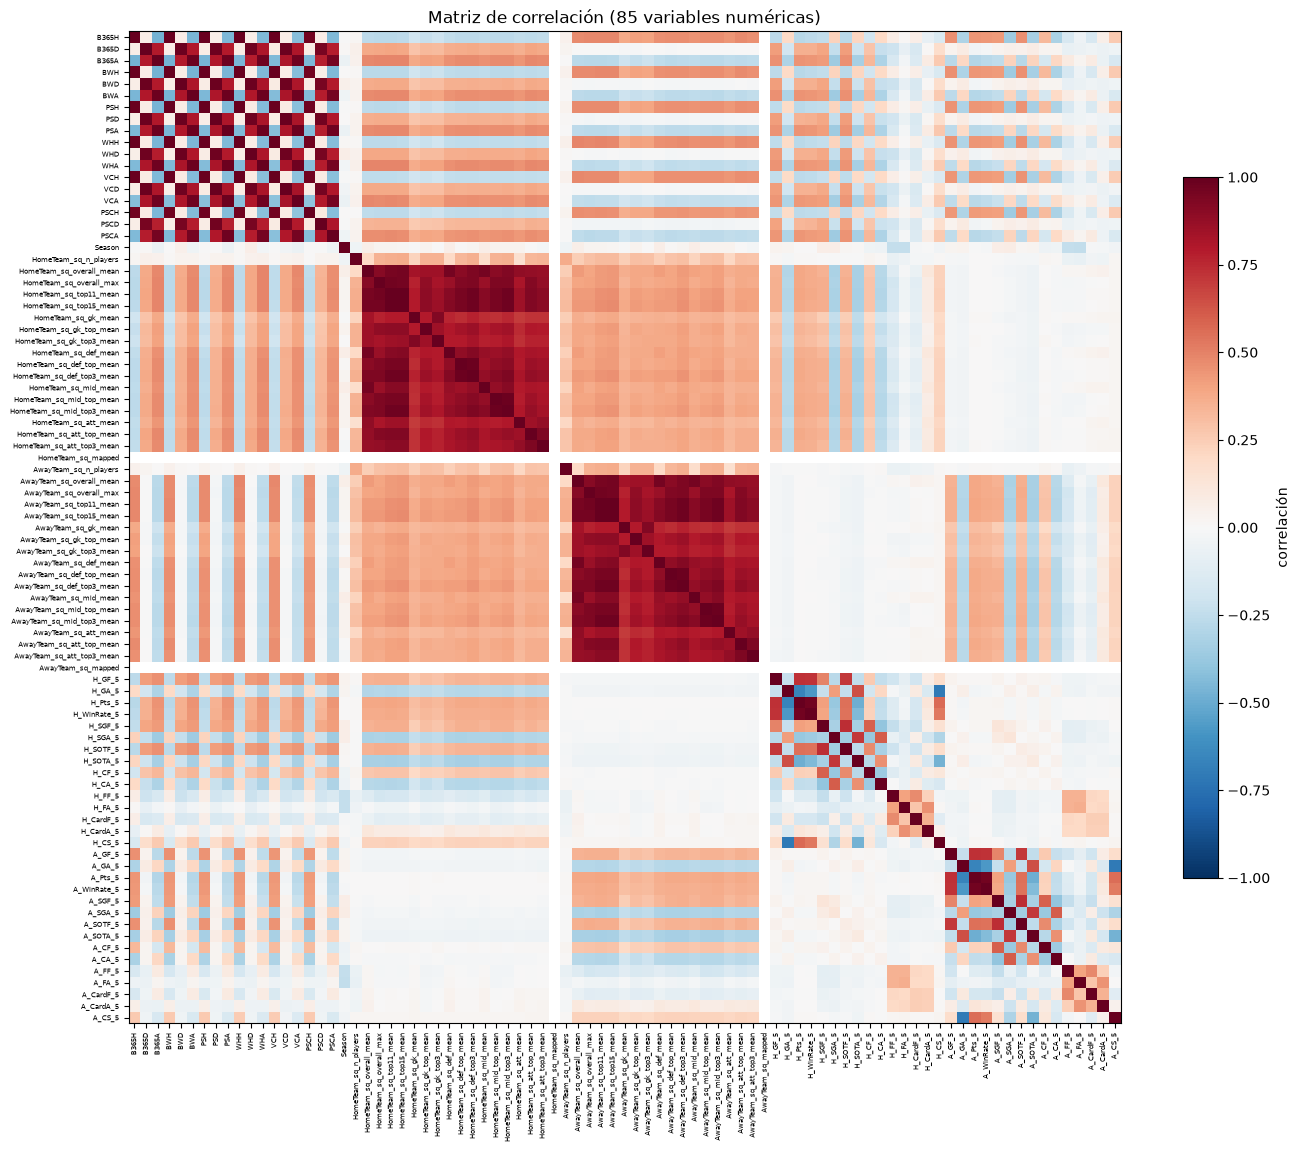

Pares con |r| > 0.95: 74 de 7225
AwayTeam_sq_top11_mean  AwayTeam_sq_top15_mean    0.999
HomeTeam_sq_top11_mean  HomeTeam_sq_top15_mean    0.999
PSH                     VCH                       0.991
BWH                     WHH                       0.990
B365H                   PSH                       0.989
                        BWH                       0.989
BWH                     PSH                       0.989
WHH                     VCH                       0.988
PSH                     WHH                       0.987
PSD                     VCD                       0.987
B365H                   VCH                       0.986
                        WHH                       0.986


In [24]:
finalizar = ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST',
                    'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']

columnas_a_borrar = [col for col in finalizar if col in df_clean.columns]
df_clean = df_clean.drop(columns=columnas_a_borrar)
print('FTR conservado como target:', 'FTR' in df_clean.columns)
df_clean.info()

num = df_clean.select_dtypes(include=[np.number]).columns
corr = df_clean[num].corr()
fig, ax = plt.subplots(figsize=(16, 13))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, shrink=0.7, label='correlación')
ax.set_title(f'Matriz de correlación ({len(corr)} variables numéricas)')
plt.show()

tri = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print('Pares con |r| > 0.95:', int((tri > 0.95).sum()), 'de', len(tri))
print(tri.head(12).round(3).to_string())

**Qué encontramos.**

- Se eliminaron 14 columnas post-partido (los goles finales y las 12 estadísticas de partido); `FTR` se conserva como target.
- Hay **74 pares con |r| > 0.95** de 7,225: `top11_mean` con `top15_mean` (0.999) y las cuotas de distintas casas entre sí (0.98–0.99). Eso confirma la multicolinealidad del mercado.

**Qué significa para nuestro caso.** Las 18 cuotas crudas dicen casi lo mismo: no tiene sentido darle al modelo 18 versiones del mismo precio.

**Decisión.** Construir un único consenso de mercado (Paso 4) y podar por correlación (Paso 5).

## Paso 4 — Mercado: consenso de probabilidades implícitas

**Qué vamos a hacer.** Convertir las cuotas de apertura en probabilidades y combinarlas entre casas.

1. Para cada casa (B365, BW, PS, WH) con las tres cuotas observadas: `p = (1/o) / Σ(1/o)`. La suma de `1/o` supera 1 por el margen de la casa; normalizar lo elimina.
2. Promediar **solo entre las casas observadas** (`nanmean`): ninguna cuota se imputa. Las casas son las de cobertura ≥ 85% (B365 99.8%, BW 96.5%, Pinnacle 95.3%, WH 88.5%; Vcbet, con 83.2% y ausente desde 2024/25, queda fuera).
3. Añadir `MKT_logit = ln(pH/pA)` (lineal en log-odds, útil para modelos lineales) y `MKT_margin` (overround medio).
4. Excluir del dataset de modelado los partidos sin cuota en ninguna casa (ya aportaron al historial de sus equipos).

**Por qué.** `AvgH/D/A` solo existen desde 2019/20; las cuotas de casas clásicas cubren todas las temporadas. Las cuotas de cierre (PSC*) **no** son features: se exportan aparte para el backtest.

In [25]:
TARGET = 'FTR'
META = ['Date', 'Date_dt', 'HomeTeam', 'AwayTeam', 'Div', 'Season']

# --- Mercado: consenso de probabilidades implicitas sobre cuotas OBSERVADAS (apertura) ---
BOOKS = [('B365H', 'B365D', 'B365A'), ('BWH', 'BWD', 'BWA'), ('PSH', 'PSD', 'PSA'), ('WHH', 'WHD', 'WHA')]
_P, _M = [], []
for h, d, a in BOOKS:
    inv = 1.0 / raw_odds[[h, d, a]].to_numpy(dtype=float)      # NaN si falta alguna de las 3
    tot = inv.sum(axis=1, keepdims=True)
    _P.append(inv / tot)
    _M.append(tot.ravel() - 1.0)
_P, _M = np.stack(_P), np.stack(_M)                             # (casas, filas, 3) / (casas, filas)
n_casas = (~np.isnan(_M)).sum(axis=0)
has_odds = n_casas > 0
with np.errstate(all='ignore'):
    P = np.nanmean(_P, axis=0)
    MARGIN = np.nanmean(_M, axis=0)
print('partidos sin ninguna cuota:', int((~has_odds).sum()), '| casas por partido (min/mediana):', int(n_casas[has_odds].min()), int(np.median(n_casas[has_odds])))

df_clean['MKT_pH'], df_clean['MKT_pD'], df_clean['MKT_pA'] = P[:, 0], P[:, 1], P[:, 2]
df_clean['MKT_logit'] = np.log(P[:, 0] / P[:, 2])
df_clean['MKT_margin'] = MARGIN

# --- Se descartan los partidos sin mercado (ya aportaron al rolling de sus equipos) ---
keep = has_odds
df_clean = df_clean.loc[keep].reset_index(drop=True)
raw_odds = raw_odds.loc[keep].reset_index(drop=True)
assert df_clean[['MKT_pH', 'MKT_pD', 'MKT_pA', 'MKT_logit', 'MKT_margin']].notna().all().all()
print('MKT_margin min/mediana/max:', df_clean['MKT_margin'].min().round(3), df_clean['MKT_margin'].median().round(3), df_clean['MKT_margin'].max().round(3))

# --- Cuotas para el backtest (NO son features): observadas, sin imputar ---
odds_bt = pd.concat([df_clean[['Div', 'Season', 'Date', 'HomeTeam', 'AwayTeam', TARGET, 'MKT_pH', 'MKT_pD', 'MKT_pA']],
                     raw_odds[['B365H', 'B365D', 'B365A', 'PSCH', 'PSCD', 'PSCA']]], axis=1)

FEATURES = [c for c in df_clean.columns if c not in META + [TARGET]]
df_final = df_clean[FEATURES + [TARGET, 'Date', 'HomeTeam', 'AwayTeam', 'Div', 'Season']].copy()
df_final['Date_dt'] = pd.to_datetime(df_final['Date'], dayfirst=True, format='mixed', errors='coerce')

cuotas_purge = [c for c in CUOTAS if c in df_final.columns]
df_final = df_final.drop(columns=cuotas_purge)
print('df_final:', df_final.shape, '| cuotas crudas eliminadas:', len(cuotas_purge))


partidos sin ninguna cuota: 31 | casas por partido (min/mediana): 1 4
MKT_margin min/mediana/max: 0.023 0.052 0.181
df_final: (36119, 78) | cuotas crudas eliminadas: 18


**Hallazgo.**

- Se excluyeron **31 partidos sin ninguna cuota**: 29 de la Süper Lig 2022/23 y 2 de la Serie A. Quedan 36,119 filas.
- Casas observadas por partido: mínimo 1, mediana 4.
- `MKT_margin` va de **0.023 a 0.181** (mediana 0.052). Todos los márgenes son positivos, como corresponde a casas reales (no hay tríos imputados incoherentes).

**Decisión.** Usar el consenso de probabilidades implícitas sobre cuotas observadas. El dataset de modelado pasa a 36,119 × 78 antes de la poda.

## Paso 5 — Poda por correlación

**Qué vamos a hacer.** Eliminar features casi duplicadas (|r| > 0.95), conservando primero las del mercado y la plantilla y luego las de forma. La correlación se calcula solo con el primer 80% de los partidos por fecha.

**Por qué.** Cap. 2 de Zheng: el filtrado por correlación es barato y no mira el target, así que no introduce leakage; debe hacerse de forma conservadora.

In [26]:
UMBRAL_CORR = 0.95
corte = df_final['Date_dt'].quantile(0.80)
TEST_SEASONS_02 = [2425, 2526]   # mismo holdout que 03-08
assert corte < df_final.loc[df_final['Season'].isin(TEST_SEASONS_02), 'Date_dt'].min(), 'el corte del 80% invade el test holdout'
train_idx = df_final['Date_dt'] <= corte

NUM_FEAT = [c for c in df_final.columns if c not in META + [TARGET]
            and pd.api.types.is_numeric_dtype(df_final[c])]
corr_m = df_final.loc[train_idx, NUM_FEAT].corr().abs()

order = (['MKT_logit', 'MKT_pH', 'MKT_pD', 'MKT_pA', 'MKT_margin',
          'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean']
         + sorted([c for c in NUM_FEAT if c.startswith(('H_', 'A_'))])
         + sorted([c for c in NUM_FEAT if c not in ['MKT_logit', 'MKT_pH', 'MKT_pD', 'MKT_pA', 'MKT_margin',
                   'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean']
                   and not c.startswith(('H_', 'A_'))]))

kept, dropped = [], set()
for c in order:
    if c not in corr_m.columns or c in dropped:
        continue
    kept.append(c)
    for d in NUM_FEAT:
        r = corr_m.loc[c, d]
        if d not in kept and d not in dropped and not (r != r) and r > UMBRAL_CORR:
            dropped.add(d)

drop_list = [d for d in dropped if d in df_final.columns]
df_final = df_final.drop(columns=drop_list)
print('eliminadas por correlación:', len(drop_list))
print('descartadas:', sorted(drop_list))

eliminadas por correlación: 16
descartadas: ['A_WinRate_5', 'AwayTeam_sq_def_top3_mean', 'AwayTeam_sq_mid_top3_mean', 'AwayTeam_sq_mid_top_mean', 'AwayTeam_sq_overall_max', 'AwayTeam_sq_overall_mean', 'AwayTeam_sq_top15_mean', 'H_WinRate_5', 'HomeTeam_sq_def_top3_mean', 'HomeTeam_sq_mid_top3_mean', 'HomeTeam_sq_mid_top_mean', 'HomeTeam_sq_overall_max', 'HomeTeam_sq_overall_mean', 'HomeTeam_sq_top15_mean', 'MKT_pA', 'MKT_pH']


**Hallazgo.** Se descartaron 14 features por correlación: `MKT_pH` y `MKT_pA` (redundantes con `MKT_logit`), `H_WinRate_5`/`A_WinRate_5` (redundantes con los puntos) y 8 medidas de plantilla (`overall_mean`, `overall_max`, `top15_mean`, `def_top3`, `mid_top3`, local y visitante).

**Decisión.** Mantener la poda. Es conservadora (umbral 0.95), no usa el target y se calculó con el primer 80% de los partidos.

## Paso 6 — Calidad de plantilla

**Qué vamos a hacer.** De las 17 medidas de plantilla por lado conservar solo la media del once mejor valorado (`top11_mean`), porque las medias por línea (defensa/medio/ataque/porteros) correlacionan 0.88–0.96 con ella. Para el resultado importa más la **ventaja neta**, así que creamos `DIF_sq_top11 = local − visitante` y quitamos la absoluta del visitante.

**Por qué.** Con el mapeo de clubes corregido la cobertura es 100%, así que las banderas `*_sq_mapped` son constantes y se eliminan.

**Limitaciones que dejamos documentadas.** `top11_mean` es el promedio de los 11 jugadores con mejor `overall` del plantel (no el once titular real) y no está normalizado por liga. Se probaron después las dos mejoras: el **once titular** (`XIz_*`) y la **normalización por liga-temporada** (`SQz_*`), ambas en el Paso 11; el resultado está en `03_preprocesamiento.ipynb` (Paso 6c).

In [27]:
KEEP_SQ = {'HomeTeam_sq_top11_mean', 'AwayTeam_sq_top11_mean'}
sq_drop = [c for c in df_final.columns if '_sq_' in c and c not in KEEP_SQ]
df_final = df_final.drop(columns=sq_drop)

df_final['DIF_sq_top11'] = df_final['HomeTeam_sq_top11_mean'] - df_final['AwayTeam_sq_top11_mean']
df_final = df_final.drop(columns=['AwayTeam_sq_top11_mean'])
print('squad granulares eliminadas:', len(sq_drop))
print('squad restantes:', [c for c in df_final.columns if '_sq_' in c or c.startswith('DIF_sq_')])

squad granulares eliminadas: 22
squad restantes: ['HomeTeam_sq_top11_mean', 'DIF_sq_top11']


**Hallazgo.** Quedan dos features de plantilla: `HomeTeam_sq_top11_mean` y `DIF_sq_top11`. Se descartaron 24 medidas granulares.

**Corrección de datos documentada.** Al revisar el mapeo de clubes (EA → football-data) se encontraron **110 colisiones**: dos clubes de EA que apuntaban al mismo equipo (por ejemplo `Arsenal` y `Arsenal de Sarandí`, `Inter` e `Inter Miami`, `Borussia Dortmund` y su filial `II`), y el join conservaba el último en orden alfabético. Afectaba a 3,588 partidos (9.9%), con equipos como Arsenal, Inter, Dortmund, Barcelona y Real Sociedad. Se resolvió con una prioridad (override > match exacto > subconjunto de tokens > fuzzy; luego misma liga; luego nombre más corto). Tras corregirlo, la MI de `DIF_sq_top11` subió de 0.067 a 0.083.

**Decisión.** Conservar solo la ventaja neta y el nivel del local. **Pendiente:** normalizar por liga y usar el once titular real (ver Paso 10 en el plan de habilidades individuales).

## Paso 7 — Ranking de Mutual Information

**Qué vamos a hacer.** Calcular `mutual_info_classif` entre cada feature y el resultado, **solo con el primer 80% de los partidos** y, como el estimador no admite NaN, solo con las filas que tienen todas las features observadas.

**Por qué.** MI mide dependencia no lineal con el target. Aquí se usa como **ranking informativo**, no para truncar: la decisión de qué bloques conservar se toma en el Paso 9 con validación cruzada temporal.

In [28]:
from sklearn.feature_selection import mutual_info_classif

NUM_FEAT = [c for c in df_final.columns if c not in META + [TARGET]
            and pd.api.types.is_numeric_dtype(df_final[c])]
assert 'Season' not in NUM_FEAT and not any(c.endswith('_Ausente') for c in NUM_FEAT)
# mutual_info_classif no admite NaN: se calcula sobre las filas de train con todas las features observadas
mask_mi = train_idx & df_final[NUM_FEAT].notna().all(axis=1)
print('filas de train usadas para MI:', int(mask_mi.sum()), 'de', int(train_idx.sum()))
y_cod = df_final.loc[mask_mi, TARGET].map({'H': 0, 'D': 1, 'A': 2}).astype(int)

mi = mutual_info_classif(df_final.loc[mask_mi, NUM_FEAT], y_cod, random_state=42, n_neighbors=3)
mi_serie = pd.Series(mi, index=NUM_FEAT).sort_values(ascending=False)
mi_serie.to_csv('../data/mi_ranking.csv', header=['mi'])

df_final = df_final[NUM_FEAT + [TARGET] + META]
print(f'{len(NUM_FEAT)} features. Ranking MI (solo train):')
print(mi_serie.round(4).to_string())


filas de train usadas para MI: 24939 de 28898
33 features. Ranking MI (solo train):
MKT_logit                 0.0979
DIF_sq_top11              0.0829
A_Pts_5                   0.0270
HomeTeam_sq_top11_mean    0.0243
MKT_pD                    0.0240
H_SGF_5                   0.0226
A_SGF_5                   0.0220
A_SOTF_5                  0.0220
H_Pts_5                   0.0186
A_GF_5                    0.0178
H_SOTF_5                  0.0173
H_GF_5                    0.0169
H_CF_5                    0.0165
H_GA_5                    0.0158
H_SOTA_5                  0.0157
A_SOTA_5                  0.0156
H_SGA_5                   0.0146
A_CA_5                    0.0141
A_GA_5                    0.0116
A_SGA_5                   0.0111
H_CA_5                    0.0099
A_CF_5                    0.0078
H_CS_5                    0.0047
A_CardF_5                 0.0042
A_CardA_5                 0.0035
A_CS_5                    0.0019
MKT_margin                0.0015
H_FF_5                   

**Hallazgo.**

- `MKT_logit` domina con MI = **0.098**, seguido de `DIF_sq_top11` (0.083).
- Todas las features de forma están por debajo de **0.027**, y cinco (`H_FA`, `H_CardA`, `A_FA`, `A_FF`, `H_CardF`) valen ≈ 0.
- Con valores tan bajos, diferencias de 0.00x están dentro del ruido del estimador.
- MI se calculó con 24,939 de 28,898 filas de train (las que no tienen NaN).

**Decisión.** **No truncar por MI.** El ranking se conserva como evidencia descriptiva y la decisión de qué bloques mantener se toma en el Paso 9 con validación cruzada temporal.

## Paso 8 — Conjuntos F1 / F2, validaciones finales y exportación

**Qué vamos a hacer.**

- **F2** = todas las features (algunas con NaN donde la fuente no publica estadísticas de partido). Lo usan los modelos que toleran NaN (árboles).
- **F1** = solo features sin NaN. Lo usan LR, SVM y MLP.
- Validar el dataset final: sin columnas post-partido, sin `Season`/banderas de temporada, rangos plausibles, alineación con `backtest_odds.csv`.
- Exportar `dataset_final.csv`, `backtest_odds.csv`, `feature_sets.json` y `mi_ranking.csv`.

In [29]:
import json
POST = ['FTHG', 'FTAG', 'HS', 'AS', 'HST', 'AST', 'HC', 'AC', 'HF', 'AF', 'HY', 'AY', 'HR', 'AR']
F2 = list(NUM_FEAT)
F1 = [f for f in NUM_FEAT if df_final[f].notna().all()]

# validaciones
assert not set(POST) & set(F2), 'hay columnas post-partido entre las features'
assert 'Season' not in F2
assert (df_final[['Date', 'HomeTeam', 'AwayTeam']].values == odds_bt[['Date', 'HomeTeam', 'AwayTeam']].values).all()
assert df_final[F1].notna().all().all()
rangos = df_final[F2].agg(['min', 'max']).T
assert (rangos.loc[[f for f in F2 if f.startswith(('H_', 'A_'))], 'min'] >= 0).all()

json.dump({'F1_sin_nan': F1, 'F2_completo': F2, 'target': TARGET, 'meta': META}, open('../data/feature_sets.json', 'w'), indent=1)
df_final.to_csv("../data/dataset_final.csv", index=False)
odds_bt.to_csv("../data/backtest_odds.csv", index=False)

print('dataset_final:', df_final.shape, '| backtest_odds:', odds_bt.shape)
print('F1:', len(F1), 'features sin NaN:', F1)
print('F2:', len(F2), 'features | con NaN:', len([f for f in F2 if f not in F1]))
print('distribucion del target:', df_final[TARGET].value_counts(normalize=True).round(3).to_dict())

dataset_final: (36119, 40) | backtest_odds: (36119, 15)
F1: 13 features sin NaN: ['HomeTeam_sq_top11_mean', 'H_GF_5', 'H_GA_5', 'H_Pts_5', 'H_CS_5', 'A_GF_5', 'A_GA_5', 'A_Pts_5', 'A_CS_5', 'MKT_pD', 'MKT_logit', 'MKT_margin', 'DIF_sq_top11']
F2: 33 features | con NaN: 20
distribucion del target: {'H': 0.444, 'A': 0.307, 'D': 0.25}


**Hallazgo.**

- `dataset_final.csv`: **36,119 × 40** (33 features + target + metadatos).
- **F1** = 13 features sin NaN. **F2** = 33 features, de las cuales 20 tienen NaN.
- Distribución del target: H = 44.4%, D = 25.0%, A = 30.7%.
- Todas las validaciones pasaron: sin columnas post-partido, sin `Season`/banderas de temporada, rangos plausibles y alineación con `backtest_odds.csv`.

**Decisión.** Congelar este dataset como entrada del modelado.

## Paso 10 — Habilidades individuales del once titular

**Qué vamos a hacer.** Replicar la idea de Stübinger, Mangold & Knoll (Appl. Sci. 2020, 10(1), 46): en lugar del `overall` agregado del plantel, describir a cada equipo por las **habilidades individuales de su once titular**.

1. Tomar los 11 titulares de cada club y temporada con `club_position` ∉ {SUB, RES} (el once por defecto del juego, equivalente al "once declarado" del paper).
2. Armonizar **33 habilidades** presentes en los 12 snapshots (cruce, definición, cabeceo, regate, aceleración, resistencia, 5 de portero…). Los nombres difieren entre versiones (`attacking_crossing` vs `crossing`). Se descarta `composure`: no existe en FIFA 15 ni FIFA 16 (se introdujo en FIFA 17).
3. Para cada habilidad de campo, el **promedio de los 4 mejores jugadores no porteros** (el paper usa el top-4 porque raramente hay más de 4 en una misma zona); para las 5 habilidades de portero, el valor del portero titular.
4. Unir a cada partido y calcular la **diferencia local − visitante** (`SK_*`): 33 features.
5. Añadir los **targets de goles**: `FTHG`, `FTAG` y `GD = FTHG − FTAG`.

**Por qué.** Las medidas agregadas (`top11_mean`) no distinguen estilos (un equipo de ataque fuerte y defensa débil). Si hay información individual que el mercado no recoge, está aquí.

**Salida.** `dataset_skills.csv` (alineado fila a fila con `dataset_final.csv`) y la clave `SK_habilidades` en `feature_sets.json`.

In [30]:
from pathlib import Path

PL = Path('../data/players/raw')
CM = pd.read_csv('../data/players/club_map.csv')            # (season, club) -> (div, team) de football-data

# nombre armonizado -> nombre en los snapshots 2015-2024 y 2026 (FC25 usa el nombre armonizado)
SK_OLD = {
    'crossing': 'attacking_crossing', 'finishing': 'attacking_finishing', 'heading_accuracy': 'attacking_heading_accuracy',
    'short_passing': 'attacking_short_passing', 'volleys': 'attacking_volleys',
    'dribbling': 'skill_dribbling', 'curve': 'skill_curve', 'fk_accuracy': 'skill_fk_accuracy',
    'long_passing': 'skill_long_passing', 'ball_control': 'skill_ball_control',
    'acceleration': 'movement_acceleration', 'sprint_speed': 'movement_sprint_speed', 'agility': 'movement_agility',
    'reactions': 'movement_reactions', 'balance': 'movement_balance',
    'shot_power': 'power_shot_power', 'jumping': 'power_jumping', 'stamina': 'power_stamina',
    'strength': 'power_strength', 'long_shots': 'power_long_shots',
    'aggression': 'mentality_aggression', 'interceptions': 'mentality_interceptions', 'positioning': 'mentality_positioning',
    'vision': 'mentality_vision', 'penalties': 'mentality_penalties',
    'defensive_awareness': 'defending_marking_awareness', 'standing_tackle': 'defending_standing_tackle',
    'sliding_tackle': 'defending_sliding_tackle',
    'gk_diving': 'goalkeeping_diving', 'gk_handling': 'goalkeeping_handling', 'gk_kicking': 'goalkeeping_kicking',
    'gk_positioning': 'goalkeeping_positioning', 'gk_reflexes': 'goalkeeping_reflexes',
}
GK_SK = [k for k in SK_OLD if k.startswith('gk_')]
FIELD_SK = [k for k in SK_OLD if not k.startswith('gk_')]
print('habilidades armonizadas:', len(SK_OLD), '| de campo:', len(FIELD_SK), '| de portero:', len(GK_SK))

clubes_mapeados = {(int(r.season), r.club) for r in CM.itertuples()}
partes = []
for year in range(2015, 2027):
    cols = {k: k for k in SK_OLD} if year == 2025 else dict(SK_OLD)           # FC25 ya usa nombres armonizados
    ov = 'overall_rating' if year == 2025 else 'overall'
    use = ['club_name', 'club_position', ov] + list(cols.values())
    d = pd.read_csv(PL / f'{year}.csv', usecols=use, low_memory=False)
    d = d.rename(columns={v: k for k, v in cols.items()}).rename(columns={ov: 'overall'})
    d['year'] = year
    d = d[[(year, c) in clubes_mapeados for c in d['club_name']]]
    partes.append(d[~d['club_position'].isin(['SUB', 'RES']) & d['club_position'].notna()])
xi = pd.concat(partes, ignore_index=True)
print('jugadores titulares (de clubes mapeados):', len(xi))

def agregar(g):
    if len(g) > 11:                                   # un club del snapshot 2024 trae 22 marcados como titulares
        g = g.nlargest(11, 'overall')
    gk = g[g['club_position'] == 'GK']
    campo = g[g['club_position'] != 'GK']
    out = {'n_xi': len(g), 'n_gk': len(gk), 'xi_overall': g['overall'].mean()}
    for s in FIELD_SK:
        out[s] = campo[s].nlargest(4).mean()
    for s in GK_SK:
        out[s] = gk[s].mean() if len(gk) else np.nan
    return pd.Series(out)

sk_club = xi.groupby(['year', 'club_name']).apply(agregar, include_groups=False).reset_index()
sk_club['Season'] = (sk_club['year'] - 2001) * 100 + (sk_club['year'] - 2000)      # 2015 -> 1415
cm = CM.assign(year=CM['season'].astype(int)).rename(columns={'club': 'club_name', 'div': 'Div', 'team': 'Team'})[['year', 'club_name', 'Div', 'Team']]
sk_team = sk_club.merge(cm, on=['year', 'club_name'], how='inner')
# Clubes sin portero entre los titulares marcados: las habilidades de portero se rellenan con la media de su liga y temporada
sin_gk = sk_team[GK_SK].isna().any(axis=1)
for col in GK_SK:
    sk_team[col] = sk_team[col].fillna(sk_team.groupby(['Season', 'Div'])[col].transform('mean'))
print('clubes sin portero entre los titulares (habilidades de portero imputadas con la media liga-temporada):', int(sin_gk.sum()))
print('(temporada, equipo) con habilidades:', len(sk_team), '| duplicados:', int(sk_team.duplicated(['Season', 'Div', 'Team']).sum()))
print('titulares y porteros por club -> (n_xi, n_gk):', sk_team.groupby(['n_xi', 'n_gk']).size().to_dict())

# --- union a los partidos y diferencia local - visitante
base_m = df_final[['Date', 'HomeTeam', 'AwayTeam', 'Div', 'Season']].reset_index(drop=True)
h = base_m.merge(sk_team.rename(columns={'Team': 'HomeTeam'}), on=['Season', 'Div', 'HomeTeam'], how='left')[list(SK_OLD)].to_numpy(float)
a = base_m.merge(sk_team.rename(columns={'Team': 'AwayTeam'}), on=['Season', 'Div', 'AwayTeam'], how='left')[list(SK_OLD)].to_numpy(float)
SK_COLS = ['SK_' + k for k in SK_OLD]
skills_df = pd.concat([base_m, pd.DataFrame(h - a, columns=SK_COLS)], axis=1)

# --- targets de goles, alineados con df_final (misma mascara que el mercado)
gol = raw_stats.loc[keep, ['FTHG', 'FTAG']].reset_index(drop=True)
skills_df['FTHG'], skills_df['FTAG'] = gol['FTHG'].to_numpy(), gol['FTAG'].to_numpy()
skills_df['GD'] = skills_df['FTHG'] - skills_df['FTAG']
assert len(skills_df) == len(df_final)
print('filas:', len(skills_df), '| features SK:', len(SK_COLS))
print('cobertura de SK_* por temporada (proporcion no nula):')
print(skills_df.groupby('Season')[SK_COLS].apply(lambda d: d.notna().all(axis=1).mean()).round(3).to_dict())
print('GD: media', round(skills_df['GD'].mean(), 3), '| desvio', round(skills_df['GD'].std(), 3), '| min/max', int(skills_df['GD'].min()), int(skills_df['GD'].max()))

habilidades armonizadas: 33 | de campo: 28 | de portero: 5
jugadores titulares (de clubes mapeados): 29777
clubes sin portero entre los titulares (habilidades de portero imputadas con la media liga-temporada): 4
(temporada, equipo) con habilidades: 2708 | duplicados: 0
titulares y porteros por club -> (n_xi, n_gk): {(9.0, 1.0): 5, (10.0, 0.0): 3, (10.0, 1.0): 46, (11.0, 0.0): 1, (11.0, 1.0): 2652, (11.0, 2.0): 1}
filas: 36119 | features SK: 33
cobertura de SK_* por temporada (proporcion no nula):
{1415: 1.0, 1516: 1.0, 1617: 1.0, 1718: 1.0, 1819: 1.0, 1920: 1.0, 2021: 1.0, 2122: 1.0, 2223: 1.0, 2324: 1.0, 2425: 1.0, 2526: 1.0}
GD: media 0.318 | desvio 1.838 | min/max -13 10


**Hallazgo.**

- **33 habilidades armonizadas** (28 de campo y 5 de portero) para los 12 snapshots. `composure` se descartó porque FIFA 15 y 16 no la incluyen.
- **29,777 jugadores titulares** de clubes mapeados, agrupados en 2,708 pares (temporada, equipo). El 97.9% tiene exactamente 11 titulares y un portero; 54 clubes tienen 9–10 titulares y 4 no tienen portero entre los titulares marcados (sus habilidades de portero se imputan con la media de su liga-temporada).
- **Cobertura 100%** de los 36,119 partidos en las 12 temporadas.
- **Diferencia de goles:** media +0.32, desvío 1.84, rango −13 a +10.

**Decisión.** Usar top-4 de campo + portero titular y la diferencia local − visitante (33 features `SK_*`). El snapshot de 2024/25 es de fin de temporada (sin fichajes de verano, `club_joined` máximo 25-05-2025); su efecto se evalúa con una comparación con y sin esa temporada en `04_modelo.ipynb`.

### Paso 10b — Verificación independiente y redundancia con `overall`

**Qué vamos a hacer.**

1. Recalcular a mano, con pandas simple sobre el archivo crudo, las habilidades de tres (temporada, equipo) y compararlas con la tabla.
2. Medir cuánto se parecen las `SK_*` a `DIF_sq_top11` (el `overall` agregado): si la correlación es muy alta no aportan información nueva.
3. Ranking de dependencia con el resultado (`mutual_info_classif` sobre `FTR`) y con la diferencia de goles (`mutual_info_regression`), solo con el primer 80% por fecha.

**Por qué.** El `overall` de EA se calcula a partir de estas mismas habilidades; si el ranking de MI no supera al de `DIF_sq_top11`, no hay razón para esperar mejoras.

In [31]:
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression

# 1) recalculo independiente
raw = {y: pd.read_csv(PL / f'{y}.csv', low_memory=False) for y in (2015, 2020, 2025)}
muestra = sk_club[sk_club['year'].isin([2015, 2020, 2025])].groupby('year').sample(2, random_state=3)[['year', 'club_name']].itertuples(index=False)
for year, club in muestra:
    d = raw[year]
    cn, ov = ('club_name', 'overall_rating' if year == 2025 else 'overall')
    q = d[(d[cn] == club) & ~d['club_position'].isin(['SUB', 'RES']) & d['club_position'].notna()]
    q = q.nlargest(11, ov) if len(q) > 11 else q
    campo = q[q['club_position'] != 'GK']
    col_f = 'finishing' if year == 2025 else 'attacking_finishing'
    col_g = 'gk_reflexes' if year == 2025 else 'goalkeeping_reflexes'
    esperado_f = campo[col_f].nlargest(4).mean()
    gk = q[q['club_position'] == 'GK'][col_g]
    fila = sk_club[(sk_club['year'] == year) & (sk_club['club_name'] == club)].iloc[0]
    print(f'{club:<26} {year}: finishing top-4 {esperado_f:.2f} vs tabla {fila.finishing:.2f} | titulares {len(q)}')
    assert abs(esperado_f - fila.finishing) < 1e-9
    if len(gk):
        assert abs(gk.mean() - fila.gk_reflexes) < 1e-9

# 2) redundancia con el overall agregado
dif_sq = df_final['DIF_sq_top11'].to_numpy()
corr_sq = skills_df[SK_COLS].apply(lambda s: s.corr(pd.Series(dif_sq, index=s.index))).sort_values(ascending=False)
print('\ncorrelacion de SK_* con DIF_sq_top11 (mayor, menor):')
print(corr_sq.head(5).round(2).to_dict()); print(corr_sq.tail(3).round(2).to_dict())
print('media |r|:', round(corr_sq.abs().mean(), 3))

# 3) MI con FTR y con GD (primer 80% por fecha, filas completas)
m = train_idx.to_numpy() & skills_df[SK_COLS].notna().all(axis=1).to_numpy()
X = skills_df.loc[m, SK_COLS]
mi_c = pd.Series(mutual_info_classif(X, df_final.loc[m, TARGET].map({'H': 0, 'D': 1, 'A': 2}).astype(int), random_state=42), index=SK_COLS)
mi_r = pd.Series(mutual_info_regression(X, skills_df.loc[m, 'GD'], random_state=42), index=SK_COLS)
mi_ref_c = mutual_info_classif(df_final.loc[m, ['DIF_sq_top11']], df_final.loc[m, TARGET].map({'H': 0, 'D': 1, 'A': 2}).astype(int), random_state=42)[0]
mi_ref_r = mutual_info_regression(df_final.loc[m, ['DIF_sq_top11']], skills_df.loc[m, 'GD'], random_state=42)[0]
print(f'\nfilas usadas: {int(m.sum())} | referencia DIF_sq_top11: MI(FTR) = {mi_ref_c:.4f}, MI(GD) = {mi_ref_r:.4f}')
print('MI con FTR (top 6):', mi_c.sort_values(ascending=False).head(6).round(4).to_dict())
print('MI con GD  (top 6):', mi_r.sort_values(ascending=False).head(6).round(4).to_dict())
print('SK con MI(GD) > referencia DIF_sq:', int((mi_r > mi_ref_r).sum()), 'de', len(SK_COLS))
pd.concat([mi_c.rename('mi_FTR'), mi_r.rename('mi_GD')], axis=1).sort_values('mi_GD', ascending=False).to_csv('../data/mi_skills.csv')

Middlesbrough              2015: finishing top-4 72.00 vs tabla 72.00 | titulares 11
FC Arouca                  2015: finishing top-4 61.50 vs tabla 61.50 | titulares 11
Stade de Reims             2020: finishing top-4 68.25 vs tabla 68.25 | titulares 11
Frosinone                  2020: finishing top-4 70.00 vs tabla 70.00 | titulares 11
Fiorentina                 2025: finishing top-4 80.00 vs tabla 80.00 | titulares 11
RB Leipzig                 2025: finishing top-4 79.75 vs tabla 79.75 | titulares 11

correlacion de SK_* con DIF_sq_top11 (mayor, menor):
{'SK_reactions': 0.94, 'SK_ball_control': 0.93, 'SK_short_passing': 0.92, 'SK_standing_tackle': 0.9, 'SK_dribbling': 0.9}
{'SK_balance': 0.47, 'SK_jumping': 0.45, 'SK_strength': 0.38}
media |r|: 0.73

filas usadas: 28898 | referencia DIF_sq_top11: MI(FTR) = 0.0850, MI(GD) = 0.1081
MI con FTR (top 6): {'SK_vision': 0.0717, 'SK_ball_control': 0.0712, 'SK_reactions': 0.0687, 'SK_short_passing': 0.0678, 'SK_positioning': 0.0661, 'SK_sta

**Hallazgo.**

- **Verificación independiente:** 6 pares (temporada, club) elegidos al azar de 2015, 2020 y 2025 coinciden exactamente con el recálculo manual.
- **Las habilidades son muy redundantes con el `overall` agregado:** correlación con `DIF_sq_top11` entre 0.38 (`strength`) y 0.94 (`reactions`), media |r| = 0.73. Esperable: el `overall` de EA se calcula con estas mismas habilidades.
- **Dependencia con el resultado (MI, primer 80%):**

| | MI con `FTR` | MI con `GD` |
|---|---|---|
| `DIF_sq_top11` (referencia) | **0.0850** | **0.1081** |
| Mejor habilidad | `vision` 0.0717 | `reactions` 0.0934 |

**Ninguna de las 33 habilidades** supera a la referencia en MI.

**Decisión.** Conservarlas para la prueba formal (Pasos 3–5 de `04_modelo.ipynb`), con la expectativa de que aporten poco: la dependencia con el resultado ya está capturada casi por completo por el `overall` agregado.

### Paso 10c — Exportación

**Qué vamos a hacer.** Guardar `dataset_skills.csv` (alineado con `dataset_final.csv`) y registrar el conjunto `SK_habilidades` y los targets en `feature_sets.json`.

In [32]:
fs = json.load(open('../data/feature_sets.json'))
fs['SK_habilidades'] = SK_COLS
fs['targets'] = {'clasificacion': TARGET, 'regresion': 'GD', 'goles': ['FTHG', 'FTAG']}
json.dump(fs, open('../data/feature_sets.json', 'w'), indent=1)
skills_df.to_csv('../data/dataset_skills.csv', index=False)
print('dataset_skills:', skills_df.shape, '| claves en feature_sets.json:', list(fs))
print('filas sin habilidades (algun SK en NaN):', int(skills_df[SK_COLS].isna().any(axis=1).sum()))

dataset_skills: (36119, 41) | claves en feature_sets.json: ['F1_sin_nan', 'F2_completo', 'target', 'meta', 'SK_habilidades', 'targets']
filas sin habilidades (algun SK en NaN): 0


**Hallazgo.** `dataset_skills.csv` exportado: **36,119 × 41** (llaves, 33 `SK_*`, `FTHG`, `FTAG`, `GD`), sin NaN y alineado fila a fila con `dataset_final.csv`. `feature_sets.json` ahora incluye `SK_habilidades` y `targets`.

**Decisión.** La evaluación de modelos con estas features y con el target de regresión se hace en `04_modelo.ipynb`.

## Paso 11 — Variables nuevas del mercado y de la plantilla

**Qué vamos a hacer.** Con el resto del proyecto ya claro (el precio domina), construir las variables que mejor lo describen y dos señales del propio mercado, todas conocidas antes del partido:

| Variable | Qué es | Por qué |
|---|---|---|
| `REF_logit`, `REF_pD` | `ln(pH/pA)` y `pD` de las probabilidades normalizadas de la cuota de apertura de **Pinnacle**; si Pinnacle no publicó, las del consenso de las otras casas | Pinnacle es la casa con menor margen y la más precisa; el respaldo evita perder partidos |
| `MKT_STD` | desviación estándar del logit entre las casas disponibles (0 si hay una sola) | ¿Las casas discrepan? Un partido incierto para el mercado puede serlo para el modelo |
| `PIN_GAP` | logit de Pinnacle − media del logit de las demás casas (0 si falta alguno) | Las casas "ágiles" y las "blandas" ajustan a distinto ritmo; esa brecha es información previa al partido |
| `SQz_H`, `SQz_DIF` | plantilla (`top11_mean`: los 11 mejores *overall* del plantel) del local y diferencia local − visitante, en desviaciones estándar dentro de cada liga y temporada | Quita el nivel propio de cada liga (los ratings de la Premier no son comparables con los de la liga turca) |
| `XIz_H`, `XIz_DIF` | lo mismo, pero con el **once titular** de cada club y temporada (los 11 jugadores que el juego marca como titulares, sin suplentes ni reservas) en lugar de los 11 mejores del plantel | Acerca la medida a quién juega de verdad; sigue siendo el once por defecto del club en el *snapshot*, **no** la alineación de cada partido (esa información no está en los datos) |

No se incluye `MKT_margin` en estas variables: cambia con los años (competencia entre casas) y delataría la temporada, no el partido.

plantilla: correlacion XIz_DIF con SQz_DIF 0.983 | con el resultado (H=1, D=.5, A=0): XIz_DIF 0.388 , SQz_DIF 0.39 | overall del once titular vs top-11 del plantel: media 74.35 vs 75.5
Pinnacle disponible: 95.4% | correlacion REF_logit con MKT_logit: 0.9991


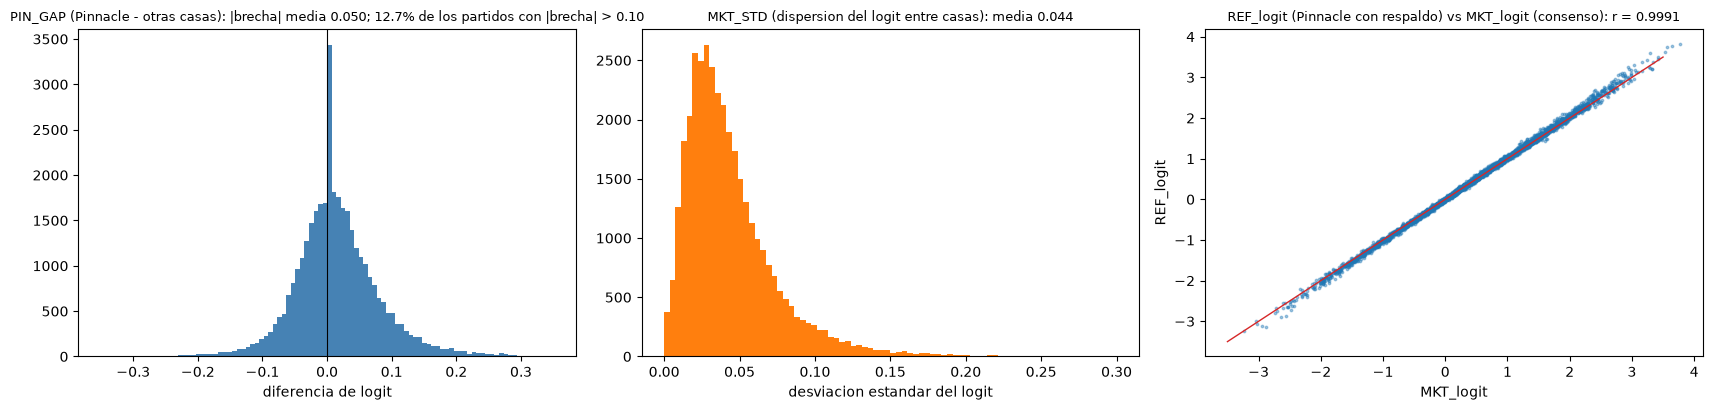

plantilla: correlacion XIz_DIF con SQz_DIF 0.983 | con el resultado (H=1, D=.5, A=0): XIz_DIF 0.388 , SQz_DIF 0.39 | overall del once titular vs top-11 del plantel: media 74.35 vs 75.5
Pinnacle disponible: 95.4% | partidos con |brecha| > 0.10: 4572


In [33]:
warnings.filterwarnings('ignore', category=RuntimeWarning)
orig_ids = np.where(keep)[0]                                   # filas de matches_clean que quedaron en df_final
LG = np.log(_P[:, :, 0] / _P[:, :, 2])                         # logit por casa, forma (4 casas, N partidos); NaN si la casa no publico
PS_ = 2                                                        # indice de Pinnacle en BOOKS
ps_ok = ~np.isnan(LG[PS_])
with np.errstate(all='ignore'):
    cons_logit, cons_pD = np.log(P[:, 0] / P[:, 2]), P[:, 1]
    REF_logit = np.where(ps_ok, LG[PS_], cons_logit); REF_pD = np.where(ps_ok, _P[PS_, :, 1], cons_pD)
    n_obs_casas = (~np.isnan(LG)).sum(0)
    MKT_STD = np.where(n_obs_casas >= 2, np.nanstd(LG, axis=0), 0.0)
    otras = np.nanmean(np.delete(LG, PS_, axis=0), axis=0)
    PIN_GAP = np.where(ps_ok & ~np.isnan(otras), LG[PS_] - otras, 0.0)
EX = pd.DataFrame({'REF_logit': REF_logit, 'REF_pD': REF_pD, 'MKT_STD': MKT_STD, 'PIN_GAP': PIN_GAP}).loc[orig_ids].reset_index(drop=True)

away_sq = df_final['HomeTeam_sq_top11_mean'] - df_final['DIF_sq_top11']
grp = df_final['Div'].astype(str) + df_final['Season'].astype(str)
allsq = pd.concat([pd.DataFrame({'g': grp, 'v': df_final['HomeTeam_sq_top11_mean']}), pd.DataFrame({'g': grp, 'v': away_sq})])
mu, sd = allsq.groupby('g')['v'].mean(), allsq.groupby('g')['v'].std()
EX['SQz_H'] = ((df_final['HomeTeam_sq_top11_mean'] - grp.map(mu)) / grp.map(sd)).to_numpy(); EX['SQz_DIF'] = (df_final['DIF_sq_top11'] / grp.map(sd)).to_numpy()
# once titular (Paso 10: sk_team trae el promedio de overall de los 11 titulares por club y temporada), normalizado por liga-temporada
xi_t = sk_team[['Season', 'Div', 'Team', 'xi_overall']]
XI_H = base_m.merge(xi_t.rename(columns={'Team': 'HomeTeam', 'xi_overall': 'v'}), on=['Season', 'Div', 'HomeTeam'], how='left')['v'].to_numpy()
XI_A = base_m.merge(xi_t.rename(columns={'Team': 'AwayTeam', 'xi_overall': 'v'}), on=['Season', 'Div', 'AwayTeam'], how='left')['v'].to_numpy()
assert not np.isnan(XI_H).any() and not np.isnan(XI_A).any(), 'faltan titulares'
allxi = pd.concat([pd.DataFrame({'g': grp.to_numpy(), 'v': XI_H}), pd.DataFrame({'g': grp.to_numpy(), 'v': XI_A})])
mux, sdx = allxi.groupby('g')['v'].mean(), allxi.groupby('g')['v'].std()
EX['XIz_H'] = ((XI_H - grp.map(mux).to_numpy()) / grp.map(sdx).to_numpy()); EX['XIz_DIF'] = ((XI_H - XI_A) / grp.map(sdx).to_numpy())
assert EX.notna().all().all() and len(EX) == len(df_final)
print('plantilla: correlacion XIz_DIF con SQz_DIF', round(float(EX.XIz_DIF.corr(EX.SQz_DIF)), 3), '| con el resultado (H=1, D=.5, A=0):', 'XIz_DIF', round(float(EX.XIz_DIF.corr(df_final['FTR'].map({'H': 1.0, 'D': 0.5, 'A': 0.0}))), 3), ', SQz_DIF', round(float(EX.SQz_DIF.corr(df_final['FTR'].map({'H': 1.0, 'D': 0.5, 'A': 0.0}))), 3), '| overall del once titular vs top-11 del plantel: media', round(float(XI_H.mean()), 2), 'vs', round(float(df_final['HomeTeam_sq_top11_mean'].mean()), 2))
print('Pinnacle disponible:', f'{ps_ok[keep].mean():.1%}', '| correlacion REF_logit con MKT_logit:', round(float(np.corrcoef(EX.REF_logit, df_final.MKT_logit)[0, 1]), 4))
fig, axs = plt.subplots(1, 3, figsize=(17, 4.2))
axs[0].hist(EX.PIN_GAP, bins=100, range=(-0.35, 0.35), color='steelblue'); axs[0].axvline(0, color='k', lw=0.8); axs[0].set_title(f'PIN_GAP (Pinnacle - otras casas): |brecha| media {EX.PIN_GAP.abs().mean():.3f}; {(EX.PIN_GAP.abs() > 0.10).mean():.1%} de los partidos con |brecha| > 0.10', fontsize=9); axs[0].set_xlabel('diferencia de logit')
axs[1].hist(EX.MKT_STD, bins=80, range=(0, 0.3), color='tab:orange'); axs[1].set_title(f'MKT_STD (dispersion del logit entre casas): media {EX.MKT_STD.mean():.3f}', fontsize=9); axs[1].set_xlabel('desviacion estandar del logit')
m_ = np.random.default_rng(0).choice(len(EX), 4000, replace=False); axs[2].scatter(df_final.MKT_logit.to_numpy()[m_], EX.REF_logit.to_numpy()[m_], s=3, alpha=0.4); axs[2].plot([-3.5, 3.5], [-3.5, 3.5], color='tab:red', lw=1)
axs[2].set_title(f"REF_logit (Pinnacle con respaldo) vs MKT_logit (consenso): r = {np.corrcoef(EX.REF_logit, df_final.MKT_logit)[0, 1]:.4f}", fontsize=9); axs[2].set_xlabel('MKT_logit'); axs[2].set_ylabel('REF_logit')
plt.tight_layout(); plt.show()
print('plantilla: correlacion XIz_DIF con SQz_DIF', round(float(EX.XIz_DIF.corr(EX.SQz_DIF)), 3), '| con el resultado (H=1, D=.5, A=0):', 'XIz_DIF', round(float(EX.XIz_DIF.corr(df_final['FTR'].map({'H': 1.0, 'D': 0.5, 'A': 0.0}))), 3), ', SQz_DIF', round(float(EX.SQz_DIF.corr(df_final['FTR'].map({'H': 1.0, 'D': 0.5, 'A': 0.0}))), 3), '| overall del once titular vs top-11 del plantel: media', round(float(XI_H.mean()), 2), 'vs', round(float(df_final['HomeTeam_sq_top11_mean'].mean()), 2))
print('Pinnacle disponible:', f'{ps_ok[keep].mean():.1%}', '| partidos con |brecha| > 0.10:', int((EX.PIN_GAP.abs() > 0.10).sum()))

**Qué encontramos.**

- Pinnacle publicó la apertura en el **95.4%** de los partidos modelables; en el resto se usa el consenso. Las variables nuevas son casi idénticas al consenso anterior (correlación **0.9991** entre `REF_logit` y `MKT_logit`), así que mezclar Pinnacle con el respaldo no introduce saltos.
- `PIN_GAP` (Pinnacle − otras casas) vale en promedio 0.05 en valor absoluto, y supera 0.10 en el **12.7%** de los partidos; `MKT_STD` es pequeña (media 0.044, máximo 0.60): las casas casi siempre coinciden.
- La plantilla normalizada por liga y temporada queda en media 0 y desvío 1 por construcción. La versión del **once titular** (`XIz_DIF`) correlaciona **0.983** con la del top-11 del plantel (`SQz_DIF`) y algo menos con el resultado (0.388 frente a 0.390): el *overall* medio del once titular es de 74.35 frente a 75.5 del top-11, pero ordena a los equipos casi igual.

**Qué significa para nuestro caso.** Usar el once titular en lugar de los 11 mejores del plantel prácticamente no cambia la medida de plantilla (correlación 0.98): el límite real es que ni una ni otra es la alineación de cada partido. Las casas discrepan poco, así que `MKT_STD` y `PIN_GAP` tienen poca variación para explicar; habrá que ver si esa pequeña discrepancia contiene información (Paso 14 y `03_preprocesamiento`) o si solo refleja cuántas casas publicaron cada partido.

## Paso 12 — Fuerza de equipo con memoria larga y goles esperados

**Qué vamos a hacer.** La forma de los últimos 5 partidos es muy ruidosa. Construir resúmenes de la **fuerza** de cada equipo con memoria más larga, todos con partidos estrictamente anteriores y con la temporada de calentamiento 2013/14:

| Variable (local − visitante) | Qué es |
|---|---|
| `ELO_DIF`, `ELO_EXP` | rating Elo por liga (K = 20, ventaja local 60, multiplicador por diferencia de goles, regresión del 25% a 1500 al empezar cada temporada) y su probabilidad esperada de que gane el local |
| `EWP5_DIF`, `EWP10_DIF` | media exponencial de puntos por partido, con vida media de 5 y 10 partidos |
| `EWG5_DIF`, `EWG10_DIF` | media exponencial de la diferencia de goles |
| `XGD`, `TOTXG` | goles esperados al estilo Dixon–Coles: ataque y defensa de cada equipo (media exponencial de goles a favor y en contra, relativa al promedio de la liga) y la media de goles de la liga; `XGD` es la diferencia local − visitante y `TOTXG` el total esperado |
| `SOT10_DIF` | media exponencial de la diferencia de tiros a puerta (una señal de calidad menos azarosa que los goles); NaN donde la fuente no publica tiros |

**Por qué.** Lo que se sabe del fútbol: los goles son escasos y ruidosos, así que un equipo se resume mejor con una memoria larga y ponderada que con los últimos cinco partidos. El Elo hace además un ajuste automático por la calidad del rival, algo que la forma de 5 partidos no hace.

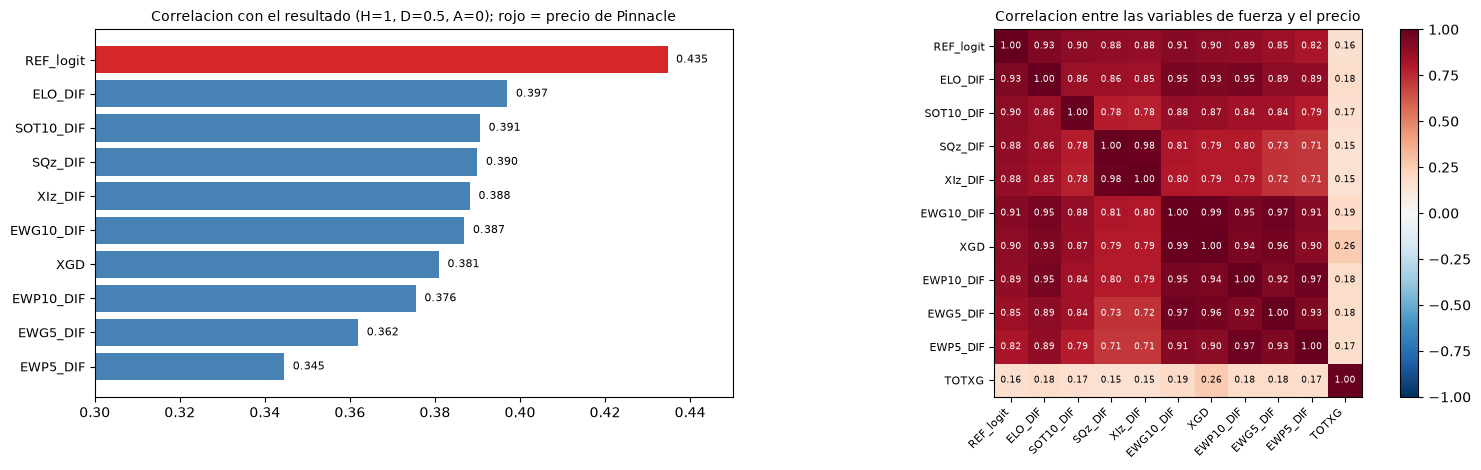

correlacion XGD con ELO_DIF: 0.935 | con REF_logit: 0.896 | NaN de SOT10_DIF: 10.0%


In [34]:
g = ev.groupby('Team')
ev['GD'] = ev['GF'] - ev['GA']; ev['SOTD'] = ev['SOTF'] - ev['SOTA']; ev['DR'] = (ev['GF'] == ev['GA']).astype(float); ev['TOT'] = ev['GF'] + ev['GA']
ewm = lambda col, h: g[col].transform(lambda s: s.shift(1).ewm(halflife=h, min_periods=1).mean())
for h_ in (5, 10):
    ev[f'EWP{h_}'] = ewm('Pts', h_); ev[f'EWG{h_}'] = ewm('GD', h_)
ev['EWGF10'], ev['EWGA10'], ev['EWSOT10'] = ewm('GF', 10), ewm('GA', 10), ewm('SOTD', 10)
ev['EWDR20'], ev['EWTOT20'] = ewm('DR', 20), ewm('TOT', 20)

def liga_prior_ev(val):
    dia = ev.assign(_v=val)[['Div', 'Date_dt', '_v']].groupby(['Div', 'Date_dt'])['_v'].agg(['sum', 'count']).reset_index().sort_values(['Div', 'Date_dt'])
    dia['cs'] = dia.groupby('Div')['sum'].transform(lambda s: s.cumsum().shift(1)); dia['cn'] = dia.groupby('Div')['count'].transform(lambda s: s.cumsum().shift(1))
    dia['prior'] = dia['cs'] / dia['cn']
    return ev[['Div', 'Date_dt']].merge(dia[['Div', 'Date_dt', 'prior']], on=['Div', 'Date_dt'], how='left')['prior'].to_numpy()
Lgf = liga_prior_ev(ev['GF'].to_numpy())                       # goles por equipo y partido de la liga, antes de la fecha
ev['ATT'] = ev['EWGF10'] / Lgf; ev['DEF'] = ev['EWGA10'] / Lgf
# valores neutros (de la temporada de calentamiento) para equipos sin historial
w_ = ev[ev['is_warm']]; NEUTRO = dict(EWP5=w_['Pts'].mean(), EWP10=w_['Pts'].mean(), EWG5=0.0, EWG10=0.0, ATT=1.0, DEF=1.0, EWDR20=w_['DR'].mean(), EWTOT20=w_['TOT'].mean())
for k, v in NEUTRO.items(): ev[k] = ev[k].fillna(v)

# liga: goles del local y del visitante antes de la fecha (a nivel de partido)
def liga_prior_base(col):
    dia = base[['Div', 'Date_dt', col]].groupby(['Div', 'Date_dt'])[col].agg(['sum', 'count']).reset_index().sort_values(['Div', 'Date_dt'])
    dia['p'] = dia.groupby('Div')['sum'].transform(lambda s: s.cumsum().shift(1)) / dia.groupby('Div')['count'].transform(lambda s: s.cumsum().shift(1))
    return base[['Div', 'Date_dt']].merge(dia[['Div', 'Date_dt', 'p']], on=['Div', 'Date_dt'], how='left')['p'].to_numpy()
base['LH'], base['LA'] = liga_prior_base('FTHG'), liga_prior_base('FTAG')
base['LH'] = base['LH'].fillna(base['FTHG'][base['is_warm']].mean()); base['LA'] = base['LA'].fillna(base['FTAG'][base['is_warm']].mean())

# Elo (por liga): el rating previo de cada partido se lee ANTES de actualizarlo con su resultado
def elo_series(mm, K=20.0, ha=60.0, regr=0.25):
    R, last, out_h, out_a = {}, {}, np.zeros(len(mm)), np.zeros(len(mm))
    for i, r in enumerate(mm.itertuples()):
        for t in (r.HomeTeam, r.AwayTeam):
            if t not in R: R[t] = 1500.0; last[t] = r.Season
            elif last[t] != r.Season: R[t] = R[t] * (1 - regr) + 1500.0 * regr; last[t] = r.Season
        rh, ra = R[r.HomeTeam], R[r.AwayTeam]; out_h[i], out_a[i] = rh, ra
        e = 1 / (1 + 10 ** (-((rh + ha) - ra) / 400)); s = 1.0 if r.FTR == 'H' else 0.5 if r.FTR == 'D' else 0.0
        gd = abs(r.FTHG - r.FTAG); mult = 1.0 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
        R[r.HomeTeam] = rh + K * mult * (s - e); R[r.AwayTeam] = ra - K * mult * (s - e)
    return out_h, out_a
eh, ea = elo_series(base); base['ELOH'], base['ELOA'] = eh, ea

# a nivel de partido: local - visitante
Hh = ev[(ev['lado'] == 'H') & ~ev['is_warm']].set_index('match_id'); Aa = ev[(ev['lado'] == 'A') & ~ev['is_warm']].set_index('match_id')
bm = base[~base['is_warm']].set_index('match_id')
F12 = pd.DataFrame(index=Hh.index)
F12['ELO_DIF'] = bm['ELOH'] - bm['ELOA']; F12['ELO_EXP'] = 1 / (1 + 10 ** (-(F12['ELO_DIF'] + 60) / 400))
for h_ in (5, 10): F12[f'EWP{h_}_DIF'] = Hh[f'EWP{h_}'] - Aa[f'EWP{h_}']; F12[f'EWG{h_}_DIF'] = Hh[f'EWG{h_}'] - Aa[f'EWG{h_}']
lamh = bm['LH'] * Hh['ATT'] * Aa['DEF']; lama = bm['LA'] * Aa['ATT'] * Hh['DEF']
F12['XGD'] = lamh - lama; F12['TOTXG'] = lamh + lama; F12['SOT10_DIF'] = Hh['EWSOT10'] - Aa['EWSOT10']
for c in F12.columns: EX[c] = F12.loc[orig_ids, c].to_numpy()
EX['DRAW_PROP'] = (Hh['EWDR20'] + Aa['EWDR20']).loc[orig_ids].to_numpy(); EX['TOTG_PROP'] = ((Hh['EWTOT20'] + Aa['EWTOT20']) / 2).loc[orig_ids].to_numpy()
yy_ = df_final['FTR'].map({'H': 1.0, 'D': 0.5, 'A': 0.0}).to_numpy()
vars_f = ['REF_logit', 'ELO_DIF', 'SOT10_DIF', 'SQz_DIF', 'XIz_DIF', 'EWG10_DIF', 'XGD', 'EWP10_DIF', 'EWG5_DIF', 'EWP5_DIF']
cor_res = pd.Series({v: float(pd.Series(EX[v]).corr(pd.Series(yy_))) for v in vars_f}).sort_values()
fig, axs = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1, 1.2]})
axs[0].barh(range(len(cor_res)), cor_res.to_numpy(), color=['tab:red' if k == 'REF_logit' else 'steelblue' for k in cor_res.index]); axs[0].set_yticks(range(len(cor_res))); axs[0].set_yticklabels(cor_res.index, fontsize=9); axs[0].set_xlim(0.3, 0.45)
for yi, v in enumerate(cor_res.to_numpy()): axs[0].text(v + 0.002, yi, f'{v:.3f}', va='center', fontsize=8)
axs[0].set_title('Correlacion con el resultado (H=1, D=0.5, A=0); rojo = precio de Pinnacle', fontsize=10)
cm_ = EX[vars_f + ['TOTXG']].corr(); im = axs[1].imshow(cm_.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1); axs[1].set_xticks(range(len(cm_))); axs[1].set_xticklabels(cm_.columns, rotation=45, ha='right', fontsize=8); axs[1].set_yticks(range(len(cm_))); axs[1].set_yticklabels(cm_.columns, fontsize=8)
for i_ in range(len(cm_)):
    for j_ in range(len(cm_)): axs[1].text(j_, i_, f'{cm_.iloc[i_, j_]:.2f}', ha='center', va='center', fontsize=6.5, color='white' if abs(cm_.iloc[i_, j_]) > 0.6 else 'black')
axs[1].set_title('Correlacion entre las variables de fuerza y el precio', fontsize=10); fig.colorbar(im, ax=axs[1], fraction=0.046)
plt.tight_layout(); plt.show()
print('correlacion XGD con ELO_DIF:', round(float(EX.XGD.corr(EX.ELO_DIF)), 3), '| con REF_logit:', round(float(EX.XGD.corr(EX.REF_logit)), 3), '| NaN de SOT10_DIF:', f'{EX.SOT10_DIF.isna().mean():.1%}')

**Qué encontramos.**

- Las variables de fuerza correlacionan **0.38–0.40** con el resultado, cerca de lo que logra el precio (`REF_logit`: 0.435): `ELO_DIF` 0.397, `SOT10_DIF` 0.391, `SQz_DIF` 0.390, `EWG10_DIF` 0.387, `XGD` 0.381.
- Están **muy correlacionadas entre sí y con el precio**: `XGD` con `ELO_DIF` 0.935 y con `REF_logit` 0.896. El Elo va de −474 a +492 puntos de diferencia (desvío 138).
- Los goles esperados totales (`TOTXG`) promedian 2.81 por partido, coherentes con la media real de la liga.
- `SOT10_DIF` tiene 10% de NaN (los partidos sin estadísticas de tiros), igual que el resto de las variables de tiros.

**Qué significa para nuestro caso.** Todas miden esencialmente lo mismo —cuánto mejor es un equipo que otro—, y lo que el mercado ya incorpora en el precio. Es una advertencia temprana de que aportarán poco sobre `REF_logit`: son buenas variables **sin cuotas** (para el benchmark independiente) y probablemente redundantes **con cuotas**.

### Paso 12b — Comprobación anti-fuga de las variables de fuerza

**Qué vamos a hacer.** Tres comprobaciones independientes:

1. **Perturbación del Elo:** alterar el resultado de 15 partidos elegidos al azar, uno por uno, y recalcular el Elo: el rating previo del partido alterado **no** debe cambiar y los de partidos posteriores sí.
2. **Recálculo a mano de `EWG10_DIF`** para 300 partidos, con un bucle sencillo sobre la tabla de partidos y fechas estrictamente anteriores.
3. **Rating previo del primer partido:** los equipos sin historial deben empezar en 1500.

**Por qué.** Una variable con historial que usa por error el resultado del propio partido da un modelo magnífico en el laboratorio y inservible en la realidad. Es el control más importante antes de usar estas variables.

In [35]:
# 1) perturbacion del Elo
pick = np.random.default_rng(0).choice(len(base), 15, replace=False); ok_prev, n_post = [], []
for i in pick:
    mp = base.copy(); mp.loc[i, ['FTHG', 'FTAG', 'FTR']] = [4, 0, 'H'] if base.loc[i, 'FTR'] != 'H' else [0, 4, 'A']
    h2, a2 = elo_series(mp)
    ok_prev.append(np.isclose(h2[i], eh[i]) and np.isclose(a2[i], ea[i])); n_post.append(int((np.abs(h2 - eh) > 1e-9).sum() + (np.abs(a2 - ea) > 1e-9).sum()))
print(f'1) Elo previo del partido alterado intacto en {int(sum(ok_prev))}/15 | partidos posteriores afectados (mediana): {int(np.median(n_post))}')
assert all(ok_prev)

# 2) recalculo a mano de EWG10_DIF
def gd_serie(team, dt, seq):
    sub = base[((base['HomeTeam'] == team) | (base['AwayTeam'] == team)) & (base['seq'] < seq)].sort_values('seq')
    return [(r.FTHG - r.FTAG) if r.HomeTeam == team else (r.FTAG - r.FTHG) for r in sub.itertuples()]
def ewm_mano(vals, h=10):
    if not vals: return 0.0
    w = 0.5 ** (np.arange(len(vals))[::-1] / h); return float(np.sum(w * np.array(vals)) / np.sum(w))
muestra = base[~base['is_warm']].sample(300, random_state=1); dif = []
for r in muestra.itertuples():
    esp = ewm_mano(gd_serie(r.HomeTeam, r.Date_dt, r.seq)) - ewm_mano(gd_serie(r.AwayTeam, r.Date_dt, r.seq))
    dif.append(abs(esp - F12.loc[r.match_id, 'EWG10_DIF']))
print('2) EWG10_DIF: 300 partidos recalculados a mano | diferencia maxima:', f'{max(dif):.2e}')
assert max(dif) < 1e-8
# 3) primer partido de cada equipo en la base: su rating previo debe ser exactamente 1500
primera = {}
for r in base.itertuples():
    for t, rt in ((r.HomeTeam, r.ELOH), (r.AwayTeam, r.ELOA)):
        primera.setdefault(t, rt)
vals = np.array(list(primera.values()))
print('3) rating previo de la primera aparicion de cada equipo (min, max):', float(vals.min()), float(vals.max()), '| equipos:', len(vals))
assert np.allclose(vals, 1500.0)

1) Elo previo del partido alterado intacto en 15/15 | partidos posteriores afectados (mediana): 3757
2) EWG10_DIF: 300 partidos recalculados a mano | diferencia maxima: 1.78e-15
3) rating previo de la primera aparicion de cada equipo (min, max): 1500.0 1500.0 | equipos: 304


**Qué encontramos.**

1. **Perturbación del Elo:** al alterar el resultado de un partido, su Elo previo **no cambió en 15 de 15 casos**, y se modificaron en promedio unos 3,757 valores posteriores: la información fluye solo hacia adelante.
2. **`EWG10_DIF` recalculada a mano** para 300 partidos con un bucle independiente: diferencia máxima de **1.8·10⁻¹⁵**.
3. **Primera aparición de cada equipo:** los 304 equipos empiezan en exactamente 1500.

**Qué significa para nuestro caso.** Las variables de historial no usan el resultado del partido que describen. Cualquier mejora que se vea en la evaluación no puede venir de una fuga de ese tipo.

## Paso 13 — Tendencia al empate y contexto del partido

**Qué vamos a hacer.** Dos grupos de variables que el mercado ya conoce pero que un modelo de fundamentos puede explotar de otra manera, y que apuntan al resultado más difícil de predecir (el empate):

| Variable | Qué es |
|---|---|
| `DRAW_PROP` | suma de la tasa de empates de ambos equipos (media exponencial, vida media 20) |
| `TOTG_PROP` | media de goles totales de los dos equipos por partido (los equipos de pocos goles empatan más) |
| `REST_H`, `REST_A`, `REST_DIF` | días desde el partido anterior de cada equipo en la base (tope de 14) |
| `CONG_H`, `CONG_A` | partidos de liga jugados en los 14 días previos |
| `SEASON_WEEK` | semanas desde la primera jornada de esa liga y temporada |
| `NEW_H`, `NEW_A` | 1 si el equipo no jugó en esa misma liga la temporada anterior (recién ascendido o recién llegado) |

**Limitación.** La base solo tiene partidos de liga: el descanso y la congestión no ven copas ni competiciones europeas, así que **subestiman** la carga de los equipos grandes. Lo que miden es el calendario de liga.

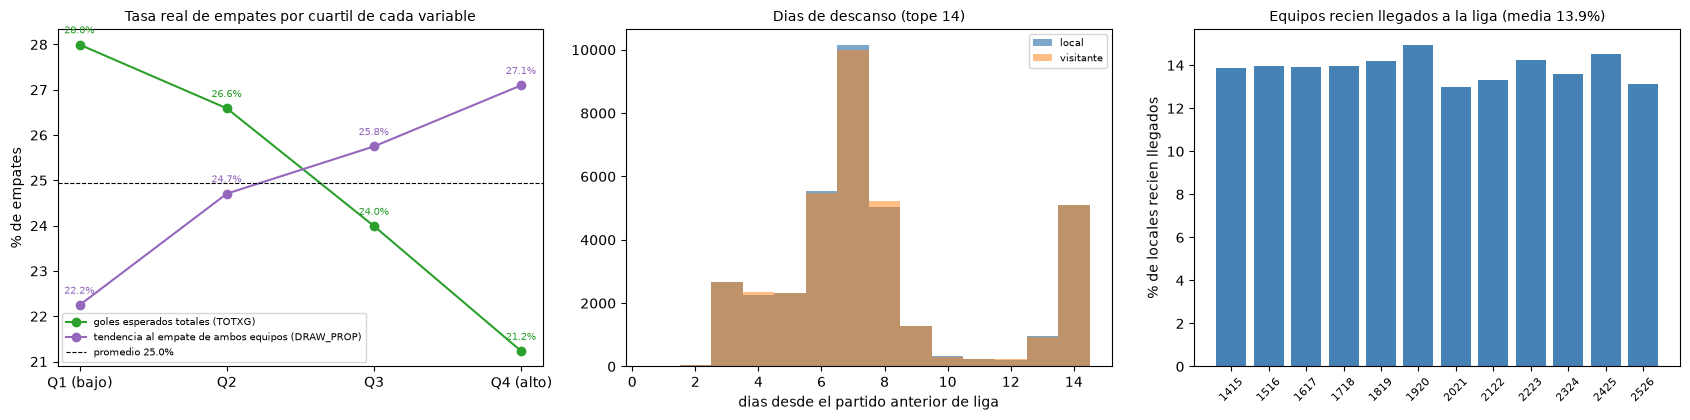

descanso medio: 7.66 dias | congestion media: 1.52 partidos en 14 dias


In [36]:
# descanso y congestion por equipo (con la temporada de calentamiento como historia)
ev2 = ev.sort_values(['Team', 'seq']).reset_index(drop=True)
rest = np.full(len(ev2), 14.0); cong = np.zeros(len(ev2)); pos = 0
for team, sub in ev2.groupby('Team', sort=False):
    d = sub['Date_dt'].to_numpy().astype('datetime64[D]'); n = len(d)
    if n > 1: rest[pos + 1: pos + n] = np.minimum((d[1:] - d[:-1]).astype(int), 14)
    cong[pos: pos + n] = np.arange(n) - np.searchsorted(d, d - np.timedelta64(14, 'D'), side='left')
    pos += n
ev2['REST'], ev2['CONG'] = rest, cong
Hh2 = ev2[(ev2['lado'] == 'H') & ~ev2['is_warm']].set_index('match_id'); Aa2 = ev2[(ev2['lado'] == 'A') & ~ev2['is_warm']].set_index('match_id')
CTX = pd.DataFrame(index=Hh2.index)
CTX['REST_H'], CTX['REST_A'] = Hh2['REST'], Aa2['REST']; CTX['REST_DIF'] = CTX['REST_H'] - CTX['REST_A']; CTX['CONG_H'], CTX['CONG_A'] = Hh2['CONG'], Aa2['CONG']
# semana de temporada
ini = base.groupby(['Div', 'Season'])['Date_dt'].transform('min'); base['SEASON_WEEK'] = (base['Date_dt'] - ini).dt.days // 7
CTX['SEASON_WEEK'] = base[~base['is_warm']].set_index('match_id')['SEASON_WEEK']
# recien llegado a la liga: no aparece en la misma liga la temporada anterior (1415 -> 1314 usa el calentamiento)
equipos = base.groupby(['Div', 'Season']).apply(lambda d: set(d['HomeTeam']) | set(d['AwayTeam']), include_groups=False).to_dict()
ant = lambda s: s - 101
bmm = base[~base['is_warm']].set_index('match_id')
CTX['NEW_H'] = [int(h not in equipos.get((d, ant(s)), set())) for h, d, s in zip(bmm['HomeTeam'], bmm['Div'], bmm['Season'])]
CTX['NEW_A'] = [int(a not in equipos.get((d, ant(s)), set())) for a, d, s in zip(bmm['AwayTeam'], bmm['Div'], bmm['Season'])]
for c in CTX.columns: EX[c] = CTX.loc[orig_ids, c].to_numpy()
assert EX.drop(columns=['SOT10_DIF']).notna().all().all()
emp = df_final['FTR'].eq('D').to_numpy()
fig, axs = plt.subplots(1, 3, figsize=(17, 4.3))
for var, col, lab in (('TOTXG', 'tab:green', 'goles esperados totales (TOTXG)'), ('DRAW_PROP', 'tab:purple', 'tendencia al empate de ambos equipos (DRAW_PROP)')):
    q = pd.qcut(EX[var], 4, labels=False); tasa = pd.Series(emp).groupby(q.to_numpy()).mean()
    axs[0].plot(range(1, 5), tasa.to_numpy() * 100, marker='o', color=col, label=lab)
    for k, v in enumerate(tasa.to_numpy()): axs[0].text(k + 1, v * 100 + 0.25, f'{v:.1%}', ha='center', fontsize=7, color=col)
axs[0].axhline(emp.mean() * 100, color='k', ls='--', lw=0.8, label=f'promedio {emp.mean():.1%}'); axs[0].set_xticks(range(1, 5)); axs[0].set_xticklabels(['Q1 (bajo)', 'Q2', 'Q3', 'Q4 (alto)']); axs[0].set_ylabel('% de empates'); axs[0].legend(fontsize=7); axs[0].set_title('Tasa real de empates por cuartil de cada variable', fontsize=10)
axs[1].hist(EX.REST_H, bins=np.arange(0.5, 15.5, 1), alpha=0.7, label='local', color='steelblue'); axs[1].hist(EX.REST_A, bins=np.arange(0.5, 15.5, 1), alpha=0.5, label='visitante', color='tab:orange'); axs[1].set_title('Dias de descanso (tope 14)', fontsize=10); axs[1].legend(fontsize=7); axs[1].set_xlabel('dias desde el partido anterior de liga')
nv = EX.groupby(df_final['Season'].to_numpy())[['NEW_H', 'NEW_A']].mean() * 100; axs[2].bar(range(len(nv)), nv['NEW_H'], color='steelblue'); axs[2].set_xticks(range(len(nv))); axs[2].set_xticklabels(nv.index, rotation=45, fontsize=8); axs[2].set_ylabel('% de locales recien llegados'); axs[2].set_title(f"Equipos recien llegados a la liga (media {EX.NEW_H.mean():.1%})", fontsize=10)
plt.tight_layout(); plt.show()
print('descanso medio:', round(float(EX.REST_H.mean()), 2), 'dias | congestion media:', round(float(EX.CONG_H.mean()), 2), 'partidos en 14 dias')

**Qué encontramos.**

- Descanso medio de 7.7 días (rango 1–14) y 1.5 partidos de liga en los 14 días previos, iguales para local y visitante.
- Los equipos **recién llegados a la liga** son el 13.9% de los locales y de los visitantes, estables entre temporadas (13–15%).
- **El empate depende de los goles esperados:** la tasa de empates baja de **28.0%** a **21.2%** del cuartil más bajo al más alto de `TOTXG`; con `DRAW_PROP` sube solo de 22.2% a 27.1%.

**Qué significa para nuestro caso.** La señal de empate más clara es la de los partidos de pocos goles esperados (7 puntos porcentuales entre extremos): un partido que se espera cerrado empata más. Es una relación que el precio quizá ya contenga a través de `pD`, algo que se comprobará en la evaluación. El descanso y la congestión de la liga solo ven el calendario de liga (no copas ni competiciones europeas), así que son medidas imperfectas de la carga real.

## Paso 14 — Revisión de todas las variables

**Qué vamos a hacer.** Poner **todas** las variables del proyecto (las base de F2, las 33 habilidades y las nuevas) en una sola tabla con la misma batería de diagnósticos, calculada **solo con el primer 80% de los partidos por fecha** (salvo el PSI):

| Columna | Qué mide |
|---|---|
| `MI` | información mutua con el resultado (no lineal) |
| `IV` | valor de información (Siddiqi) respecto de "gana el local", con 10 tramos de igual masa |
| `IV_D` | lo mismo respecto de "empate" (el resultado más difícil: una variable puede informar sobre el empate sin informar sobre el ganador) |
| `r_REF` | correlación con `REF_logit` (qué parte de la variable ya está en el precio) |
| `NaN%` | porcentaje de partidos sin valor |
| `PSI_max` | mayor índice de estabilidad entre el pasado y cada temporada de 2018/19 a 2025/26 (< 0.10 estable, > 0.25 cambio significativo) |

**Veredicto.** `inestable` (PSI > 0.25), `redundante` (|r| > 0.95 con otra variable de la tabla), `sin información` (MI < 0.003, IV < 0.02 e IV_D < 0.02) o `conservar`. Es un veredicto de **calidad de la variable**; qué aporta realmente sobre el precio se decide con validación temporal en `03_preprocesamiento.ipynb` y `08_modelo_final.ipynb`.

**Por qué.** Hasta ahora cada variable se justificó en un paso distinto (MI en el Paso 7, PSI en `03_preprocesamiento`, etc.). Una tabla única permite ver de un vistazo cuáles merecen estar y cuáles son ruido.

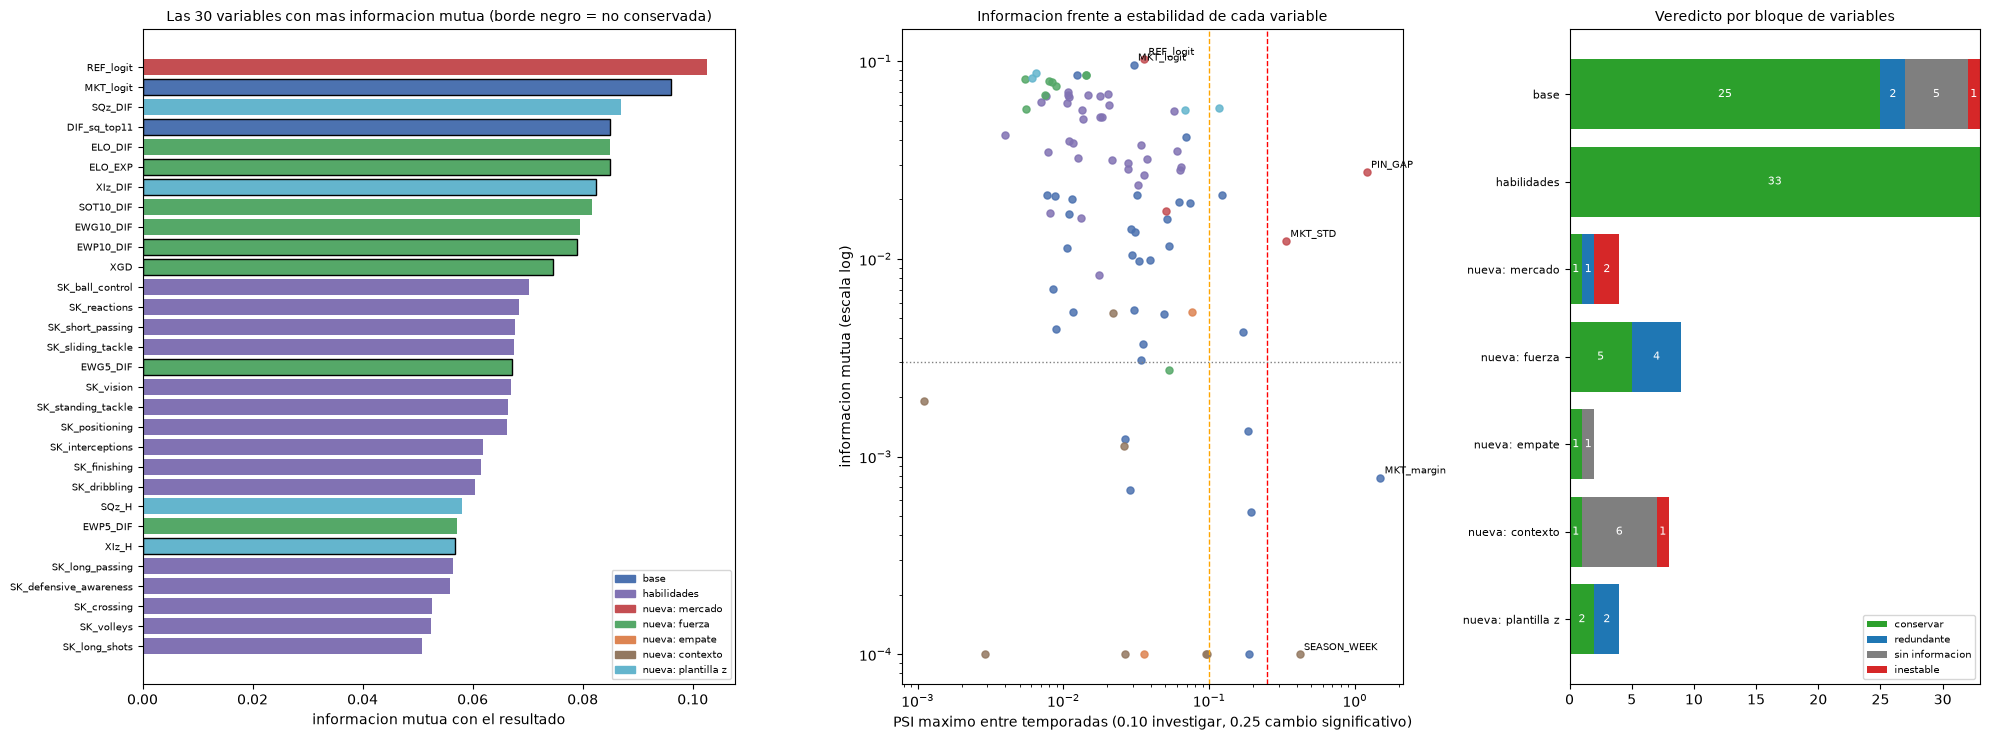

Variables NO conservadas (25): {'inestable': ['MKT_margin', 'MKT_STD', 'PIN_GAP', 'SEASON_WEEK'], 'redundante': ['MKT_logit', 'DIF_sq_top11', 'REF_pD', 'XIz_H', 'XIz_DIF', 'ELO_EXP', 'EWG5_DIF', 'EWP10_DIF', 'XGD'], 'sin informacion': ['H_FA_5', 'H_CardA_5', 'A_FF_5', 'A_FA_5', 'A_CardF_5', 'DRAW_PROP', 'REST_H', 'REST_A', 'CONG_H', 'CONG_A', 'NEW_H', 'NEW_A']}


In [37]:
from sklearn.feature_selection import mutual_info_classif
ALL = pd.concat([df_final[F2].reset_index(drop=True), skills_df[SK_COLS].reset_index(drop=True), EX.drop(columns=[c for c in EX.columns if c in F2])], axis=1)
ALL = ALL.loc[:, ~ALL.columns.duplicated()]
bloque_de = {**{c: 'base' for c in F2}, **{c: 'habilidades' for c in SK_COLS}}
GRUPOS = {'mercado': ['REF_logit', 'REF_pD', 'MKT_STD', 'PIN_GAP'], 'fuerza': ['ELO_DIF', 'ELO_EXP', 'EWP5_DIF', 'EWP10_DIF', 'EWG5_DIF', 'EWG10_DIF', 'XGD', 'TOTXG', 'SOT10_DIF'],
          'empate': ['DRAW_PROP', 'TOTG_PROP'], 'contexto': ['REST_H', 'REST_A', 'REST_DIF', 'CONG_H', 'CONG_A', 'SEASON_WEEK', 'NEW_H', 'NEW_A'], 'plantilla z': ['SQz_H', 'SQz_DIF', 'XIz_H', 'XIz_DIF']}
for gname, cols in GRUPOS.items():
    for c in cols: bloque_de[c] = 'nueva: ' + gname
yv = df_final['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy(); yb_ = (yv == 0).astype(int); yd_ = (yv == 1).astype(int)
fch = df_final['Date_dt']; tr80 = (fch <= fch.quantile(0.80)).to_numpy(); seas_ = df_final['Season'].to_numpy()
def iv_(x, yb, nb=10):
    q = np.unique(np.nanquantile(x, np.linspace(0, 1, nb + 1)[1:-1])); b = np.digitize(x, q); K = len(q) + 1
    g_ = np.array([((b == k) & (yb == 1)).sum() + 0.5 for k in range(K)]); b_ = np.array([((b == k) & (yb == 0)).sum() + 0.5 for k in range(K)])
    return float(np.sum((g_ / g_.sum() - b_ / b_.sum()) * np.log((g_ / g_.sum()) / (b_ / b_.sum()))))
def psi_(e, a, nb=10):
    e, a = e[~np.isnan(e)], a[~np.isnan(a)]
    if len(e) < 100 or len(a) < 100: return np.nan
    q = np.unique(np.nanquantile(e, np.linspace(0, 1, nb + 1)[1:-1])); pe = np.clip(np.bincount(np.digitize(e, q), minlength=len(q) + 1) / len(e), 1e-4, None); pa = np.clip(np.bincount(np.digitize(a, q), minlength=len(q) + 1) / len(a), 1e-4, None)
    return float(np.sum((pa - pe) * np.log(pa / pe)))
rows = []
for c in ALL.columns:
    x = ALL[c].to_numpy(float); m = tr80 & ~np.isnan(x)
    if m.sum() < 500 or np.nanstd(x[m]) == 0: rows.append(dict(variable=c, bloque=bloque_de.get(c, '?'), MI=np.nan, IV=np.nan, IV_D=np.nan)); continue
    mi = mutual_info_classif(x[m].reshape(-1, 1), yv[m], random_state=42, n_neighbors=3)[0]
    ps = [psi_(x[seas_ < s], x[seas_ == s]) for s in [1819, 1920, 2021, 2122, 2223, 2324, 2425, 2526]]
    rows.append(dict(variable=c, bloque=bloque_de.get(c, '?'), MI=mi, IV=iv_(x[m], yb_[m]), IV_D=iv_(x[m], yd_[m]), r_REF=float(pd.Series(x).corr(EX['REF_logit'])), NaN_pct=100 * float(np.isnan(x).mean()), PSI_max=np.nanmax(ps)))
rev = pd.DataFrame(rows).set_index('variable')
corrm = ALL.corr().abs(); red = set()
orden_pref = list(rev.sort_values('MI', ascending=False).index)
for i_, c in enumerate(orden_pref):
    if c in red: continue
    for d_ in orden_pref[i_ + 1:]:
        if d_ not in red and corrm.loc[c, d_] > 0.95: red.add(d_)
def veredicto(c, r):
    if r.PSI_max > 0.25: return 'inestable'
    if c in red: return 'redundante'
    if (r.MI < 0.003) and (r.IV < 0.02) and (r.IV_D < 0.02): return 'sin informacion'
    return 'conservar'
rev['veredicto'] = [veredicto(c, r) for c, r in rev.iterrows()]
rev.to_csv('../data/revision_variables.csv')
colb = {'base': '#4C72B0', 'habilidades': '#8172B3', 'nueva: mercado': '#C44E52', 'nueva: fuerza': '#55A868', 'nueva: empate': '#DD8452', 'nueva: contexto': '#937860', 'nueva: plantilla z': '#64B5CD'}
fig, axs = plt.subplots(1, 3, figsize=(20, 7.5), gridspec_kw={'width_ratios': [1.3, 1.1, 0.9]})
top = rev.sort_values('MI', ascending=False).head(30)[::-1]
axs[0].barh(range(len(top)), top.MI.to_numpy(), color=[colb[b_] for b_ in top.bloque], edgecolor=['black' if v != 'conservar' else 'none' for v in top.veredicto]); axs[0].set_yticks(range(len(top))); axs[0].set_yticklabels(top.index, fontsize=7)
axs[0].set_title('Las 30 variables con mas informacion mutua (borde negro = no conservada)', fontsize=10); axs[0].set_xlabel('informacion mutua con el resultado')
handles = [plt.Rectangle((0, 0), 1, 1, color=v) for v in colb.values()]; axs[0].legend(handles, colb.keys(), fontsize=7, loc='lower right')
r2 = rev.dropna(subset=['MI', 'PSI_max'])
for b_, g_ in r2.groupby('bloque'): axs[1].scatter(g_.PSI_max.clip(lower=1e-3), g_.MI.clip(lower=1e-4), s=26, color=colb[b_], label=b_, alpha=0.85)
axs[1].set_xscale('log'); axs[1].set_yscale('log'); axs[1].axvline(0.10, color='orange', ls='--', lw=1); axs[1].axvline(0.25, color='red', ls='--', lw=1); axs[1].axhline(0.003, color='gray', ls=':', lw=1)
for v_, r_ in r2.iterrows():
    if r_.PSI_max > 0.25 or r_.MI > 0.09: axs[1].annotate(v_, (max(r_.PSI_max, 1e-3), max(r_.MI, 1e-4)), fontsize=7, xytext=(3, 3), textcoords='offset points')
axs[1].set_xlabel('PSI maximo entre temporadas (0.10 investigar, 0.25 cambio significativo)'); axs[1].set_ylabel('informacion mutua (escala log)'); axs[1].set_title('Informacion frente a estabilidad de cada variable', fontsize=10)
ct = pd.crosstab(rev.bloque, rev.veredicto).reindex(columns=['conservar', 'redundante', 'sin informacion', 'inestable'], fill_value=0); ct = ct.loc[list(colb.keys())]
left = np.zeros(len(ct)); colv = {'conservar': 'tab:green', 'redundante': 'tab:blue', 'sin informacion': 'tab:gray', 'inestable': 'tab:red'}
for v_ in ct.columns:
    axs[2].barh(range(len(ct))[::-1], ct[v_], left=left, color=colv[v_], label=v_)
    for yi, l_, w_ in zip(range(len(ct))[::-1], left, ct[v_]):
        if w_ > 0: axs[2].text(l_ + w_ / 2, yi, int(w_), ha='center', va='center', fontsize=8, color='white')
    left += ct[v_].to_numpy()
axs[2].set_yticks(range(len(ct))[::-1]); axs[2].set_yticklabels(ct.index, fontsize=8); axs[2].legend(fontsize=7, loc='lower right'); axs[2].set_title('Veredicto por bloque de variables', fontsize=10)
plt.tight_layout(); plt.show()
print('Variables NO conservadas (%d):' % int((rev.veredicto != 'conservar').sum()), {v_: list(rev.index[rev.veredicto == v_]) for v_ in ('inestable', 'redundante', 'sin informacion')})

**Qué encontramos.** Veredicto de las 93 variables (calculado con el primer 80% de los partidos):

| Bloque | Conservar | Redundante | Sin información | Inestable |
|---|---|---|---|---|
| Base (F2) | 25 | 2 | 5 | 1 |
| Habilidades | 33 | 0 | 0 | 0 |
| Nuevas: mercado | 1 | 1 | 0 | 2 |
| Nuevas: fuerza | 5 | 4 | 0 | 0 |
| Nuevas: empate | 1 | 0 | 1 | 0 |
| Nuevas: contexto | 1 | 0 | 6 | 1 |
| Nuevas: plantilla normalizada (top-11 y once titular) | 2 | 2 | 0 | 0 |

- **Las más informativas** son las del precio y la fuerza: `REF_logit` (MI 0.103, IV 0.698), `SQz_DIF` (0.087), `ELO_DIF` (0.085), `SOT10_DIF` (0.082) y `EWG10_DIF` (0.079); entre las base, `MKT_logit` (0.096) y `DIF_sq_top11` (0.085) quedan como redundantes de sus versiones nuevas (correlación > 0.95).
- **Inestables:** `MKT_margin` (PSI 1.50), `PIN_GAP` (1.21), `SEASON_WEEK` (0.42) y `MKT_STD` (0.34). Las dos señales nuevas del mercado dependen de **cuántas casas publican** cada temporada (desde 2024/25 faltan WH y VC), así que miden la composición del conjunto de casas y no el partido.
- **Sin información:** cinco variables de forma de faltas y tarjetas, el descanso y la congestión de cada equipo por separado, los equipos recién llegados y `DRAW_PROP`. (`REST_DIF` y `TOTG_PROP` se conservan por poco.)
- Las 33 habilidades se conservan todas (MI 0.03–0.07), aunque su información es mayormente la misma que la de la plantilla (ver más arriba).

**Qué significa para nuestro caso.** Casi todo lo informativo es una versión del mismo contenido: el nivel de los equipos, que el precio ya resume. Las ideas pensadas para aportar algo distinto —discrepancia entre casas, contexto, descanso, equipos recién ascendidos— o son inestables o no tienen información. Queda por ver, con validación temporal, si alguna (`TOTXG`, `TOTG_PROP`, `SOT10_DIF`) aporta sobre el precio.

## Paso 15 — Exportación de las variables nuevas

**Qué vamos a hacer.** Guardar las variables nuevas en `dataset_extra.csv` (alineado fila a fila con `dataset_final.csv`, con las llaves `Date`, `HomeTeam`, `AwayTeam`, `Season`) y registrar sus grupos en `feature_sets.json` bajo la clave `EXTRA`. `dataset_final.csv`, F1 y F2 **no** cambian.

**Por qué.** Los cuadernos 03 y 04 evalúan los bloques base y deben seguir reproduciendo sus resultados exactamente; las variables nuevas se evalúan aparte (`03_preprocesamiento.ipynb`) y la elegida entra en el modelo final (`08_modelo_final.ipynb`).

In [38]:
EXTRA = pd.concat([df_final[['Date', 'HomeTeam', 'AwayTeam', 'Season']].reset_index(drop=True), EX], axis=1)
assert (EXTRA[['Date', 'HomeTeam', 'AwayTeam']].values == df_final[['Date', 'HomeTeam', 'AwayTeam']].values).all()
EXTRA.to_csv('../data/dataset_extra.csv', index=False)
fs = json.load(open('../data/feature_sets.json')); fs['EXTRA'] = GRUPOS; fs['EXTRA_con_NaN'] = ['SOT10_DIF']
json.dump(fs, open('../data/feature_sets.json', 'w'), indent=1)
print('dataset_extra:', EXTRA.shape, '| grupos:', {k: len(v) for k, v in GRUPOS.items()}, '| claves en feature_sets.json:', list(fs))

dataset_extra: (36119, 31) | grupos: {'mercado': 4, 'fuerza': 9, 'empate': 2, 'contexto': 8, 'plantilla z': 4} | claves en feature_sets.json: ['F1_sin_nan', 'F2_completo', 'target', 'meta', 'SK_habilidades', 'targets', 'EXTRA', 'EXTRA_con_NaN']


**Qué encontramos.** `dataset_extra.csv` exportado: **36,119 filas × 31 columnas** (4 llaves y 27 variables nuevas, de las cuales solo `SOT10_DIF` tiene NaN), y `feature_sets.json` ahora incluye la clave `EXTRA` con los cinco grupos. `dataset_final.csv`, `dataset_skills.csv` y `backtest_odds.csv` son **idénticos** a los de antes de reescribir el EDA y este cuaderno (comprobado valor por valor).

**Qué significa para nuestro caso.** Los cuadernos 03 y 04 siguen reproduciendo exactamente sus resultados, y las variables nuevas se evalúan por separado.

## Resumen de decisiones

| Paso | Decisión | Justificación |
|---|---|---|
| 0 | Usar solo valores **observados** (el EDA ya no imputa nada) | Una sola fuente de verdad; sin datos inventados |
| 1 | Forma de 5 partidos con calentamiento 2013/14 y ventana acolchada | Historial real desde la primera jornada; sin mirar el futuro |
| 2 | Verificar por recálculo independiente | 600 comprobaciones, diferencia 0.0 |
| 2b | **No imputar** estadísticas ausentes; F1 sin NaN, F2 con NaN | 3,959 partidos (11%) sin esas estadísticas en la fuente |
| 3 | Descartar columnas post-partido | Evitar leakage |
| 4 | Mercado = consenso de probabilidades implícitas observadas; excluir 31 partidos sin cuota | Cobertura completa; márgenes coherentes |
| 5 | Poda por correlación > 0.95 (14 features) | Redundancia; sin leakage |
| 6 | Plantilla: `top11_mean` y `DIF_sq_top11` | Resto de medidas correlacionan 0.88–0.96 |
| 7 | MI como ranking, no como corte | Todas las MI son bajas; la decisión de qué bloques conservar se toma con validación temporal |
| 8 | Congelar `dataset_final.csv` (F1: 13, F2: 33) | Entrada del modelado |
| 10 | 33 habilidades individuales del once titular (top-4 de campo + portero, diferencia local − visitante) y targets de goles | Enfoque de Stübinger et al.; 100% de cobertura; muy correlacionadas con el `overall` (media |r| = 0.73) |

| 11 | Precio de referencia de Pinnacle con respaldo; `MKT_STD` y `PIN_GAP`; plantilla normalizada por liga | Pinnacle es la casa más precisa; `MKT_STD` y `PIN_GAP` resultaron inestables (PSI 0.34 y 1.21) |
| 12 | Fuerza con memoria larga: Elo, EWMA, goles esperados, tiros a puerta | Mejores que la forma de 5 partidos (se confirma en `03_preprocesamiento`); sin fuga (perturbación y recálculo a mano) |
| 13 | Tendencia al empate y contexto | Solo `TOTXG` y `TOTG_PROP` muestran relación con el empate; descanso, congestión y recién llegados no tienen información |
| 14 | Tabla de revisión con veredicto por variable | 25 de 93 variables (8 base y 17 nuevas) se marcan redundantes, inestables o sin información |
| 15 | `dataset_extra.csv` aparte de `dataset_final.csv` | F1/F2 no cambian; las nuevas se evalúan en `05` y `08` |

**Siguiente.** La comparación de modelos y el aporte de cada bloque de features se evalúan con validación cruzada temporal en `notebooks/04_modelo.ipynb`.